<h1 align="center" style="text-align:center">ArtELingo CBM: Tuesday proof of concept</h1>

<figure align="center" style="margin:8px auto 12px;text-align:center">
<img src="figures/magritte_key_of_dreams.jpg" width="680" style="max-width:100%" alt="Four panels: a bag labelled 'le ciel', a penknife labelled 'l'oiseau', a leaf labelled 'la table' and a sponge labelled 'l'éponge'">
<figcaption style="opacity:0.75;font-size:0.92em;margin-top:4px">René Magritte, <i>La clé des songes</i> (The Key of Dreams, 1927)</figcaption>
</figure>

<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:12px 16px;margin:6px 0 12px;box-sizing:border-box;max-width:100%">

<b>TL;DR.</b> We build the obvious concept bottleneck for ArtELingo (painting, then visual
concepts, then emotion) and test the assumptions behind it. It works, modestly: its top
guess matches the chosen emotion only slightly more often than always guessing
"contentment", and it removes about 5% of the error left by each language's label habits,
close to a black box and close to how much the painting itself decides. The three
languages do differ, but mostly in how each uses the nine labels, not in how each reads
what is visible. Another encoder or concepts in each language barely change this, and the
native words that help most are feeling words: the label coming back in as a concept.

</div>

<div style="border:1.5px solid #d4a27f;background:rgba(212,162,127,0.09);border-radius:6px;padding:10px 16px;margin:6px 0 10px;box-sizing:border-box;max-width:100%">
<div style="font-size:1.05em;line-height:1.5;font-style:italic">“the limitation of our own, the stark impossibility of thinking that”</div>
<div style="opacity:0.75;margin-top:3px;font-size:0.92em">Foucault, The Order of Things (1966), preface, on Borges’s imaginary encyclopedia</div>
</div>

The obvious way to model ArtELingo is a concept bottleneck: painting, then visual
concepts, then emotion. We start by building it. It works, modestly. The rest of the
notebook asks why it works as much as it does, and no more. Part I looks at where
language shows up: in label habits, or in how specific paintings are read. A hinge
section measures how much the painting itself decides, and checks the model against
that. Part II tests whether the model's concepts behave as promised.

Each section asks one question, states a hypothesis, and compares the result with what
we would see if the effect were absent.

**Where we use an LLM.** Claude Opus 5.5 wrote the generic concept list the model uses from
section 1 on, to a brief: plain visual concepts, no emotion words, nothing
culture-specific. It also translates the Arabic and Chinese examples into English, marked
(trans.), only so we can read them. In section 8 it translates the concept list into
Arabic and Chinese and labels the native words (feeling word, concept, or not a concept,
and which words mean the same). I checked the Chinese translation and labelled the English
and Chinese words myself (agreement in a footnote to section 8); the Arabic translation
and labels are unchecked.

**To run:** `uv sync`, then `uv run jupyter lab` and Restart & Run All. The first run
downloads the images and embeds them; later runs reuse the files in `data/`.

Load the settings from `config.yaml` and print them, so every run shows what it used.

In [1]:
import logging
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.exceptions import ConvergenceWarning

from artcbm import analysis, cbm, data, embed, plots, show
from artcbm.config import REPO_ROOT, load_config, resolve_device, set_seeds

cfg = load_config()
set_seeds(cfg.seed)
DEVICE = resolve_device(cfg.device)
LANGS, EMOS = list(cfg.data.languages), list(cfg.data.emotions)
plots.setup_style()
pd.set_option("display.precision", 3)
warnings.filterwarnings("ignore", message="IProgress not found")  # plain progress bars
# A few weakly regularised fits in the forward model's C search stop early; they are
# rarely chosen, and the chosen settings are what count.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)

print((REPO_ROOT / "config.yaml").read_text())
print("device:", DEVICE)

seed: 42
device: auto                 # auto picks mps on Apple Silicon, else cpu

data:
  # ArtELingo-28 train CSV (no images); see notebook section 0 for where it comes from
  annotations_csv: data/raw/artelingo28_train_final.csv
  annotations_parquet: data/annotations.parquet
  # images fetched from wikiart.org by painting slug (only the kept paintings)
  images_dir: data/images
  languages: [english, arabic, chinese]   # exact strings in the CSV (lowercase)
  emotions: [amusement, awe, contentment, excitement, anger, disgust, fear, sadness, something else]
  min_annotations_per_language: 5
  max_paintings: 8000        # cap; 843 pass the filter and 840 have images, so no-op for now

embedding:
  model: ViT-B-32-quickgelu   # the OpenAI weights were trained with QuickGELU
  pretrained: openai
  batch_size: 64
  cache_dir: data/embeddings
  # multilingual CLIP for the encoder swap and non-English vocabularies
  multilingual_model: xlm-roberta-base-ViT-B-32
  multilingual_pretrained: 

## 0. The data

ArtELingo (Mohamed et al., EMNLP 2022) asked people to look at about 80,000 WikiArt
paintings, pick the emotion a painting evokes most from nine options (four positive,
four negative, and "something else"), and explain their choice in a sentence. Each
painting has five annotations in English, Arabic and Chinese, about 1.2 million in all.
English annotators came from Amazon Mechanical Turk (about 6,400 people), Arabic
annotators mainly from universities in Saudi Arabia and Egypt (about 660), and Chinese
annotators through Baidu (about 750). ArtELingo-28 (Mohamed et al., EMNLP 2024) took 2,000
of these paintings and added 25 more languages, with about nine annotators each; its
English, Arabic and Chinese rows come from ArtELingo.

We use the ArtELingo-28 training file. Each row is one person's emotion label for one
WikiArt painting, with a short explanation. We keep the English, Arabic and Chinese
annotations, and only the paintings that have at least five in each language and whose
image we could download from wikiart.org. For each of those paintings we take exactly
five annotations per language, so every language sees every painting equally often.
Section 8 also reads explanations from the original ArtELingo release, only for paintings
outside our set and only their text.

Load and filter the annotations, download the images (only the first run does this),
balance, and count what is left.

In [2]:
ann = data.load_annotations(cfg)
kept = data.filter_paintings(
    ann, LANGS, cfg.data.min_annotations_per_language, cfg.data.max_paintings, cfg.seed
)
painting_images = kept.drop_duplicates("painting").set_index("painting")["image_name"]
missing = data.fetch_wikiart_images(painting_images, cfg.data.images_dir)
painting_images = painting_images[~painting_images.isin(missing["image_name"])]
kept = kept[kept["painting"].isin(painting_images.index)]

bal = data.balance_per_painting(kept, cfg.data.min_annotations_per_language, cfg.seed)
labels = data.label_array(bal, LANGS, EMOS)  # (paintings, languages, annotations)


def image_path(painting):
    return cfg.data.images_dir / painting_images[painting]


summary = pd.DataFrame(
    {
        "all rows": ann["language"].value_counts(),
        "rows on kept paintings": kept["language"].value_counts(),
        "balanced rows": bal["language"].value_counts(),
    }
).loc[LANGS]
print(
    f"paintings: {ann['painting'].nunique()} in data, {bal['painting'].nunique()} kept "
    f"({len(missing)} dropped because wikiart.org no longer has the image)"
)
print(f"balanced table: {len(bal)} rows = paintings x {len(LANGS)} languages x {labels.shape[2]}")
summary

paintings: 1322 in data, 840 kept (3 dropped because wikiart.org no longer has the image)
balanced table: 12600 rows = paintings x 3 languages x 5


,all rows,rows on kept paintings,balanced rows
language,,,
english,6515,4401,4200
arabic,6067,4226,4200
chinese,6935,4424,4200


The file in numbers: how many rows and paintings each language has, how long the
explanations are, and what kind of paintings we keep.

In [3]:
per_painting = ann.groupby(["painting", "language"]).size().unstack(fill_value=0)[LANGS]
overview = pd.DataFrame(
    {
        "rows in the file": ann["language"].value_counts()[LANGS],
        "paintings in the file": (per_painting > 0).sum(),
        "annotations per painting (median)": per_painting.where(per_painting > 0).median(),
        "explanation length (median characters)": bal.groupby("language")["caption"].apply(
            lambda s: s.str.len().median()
        )[LANGS],
    }
).T.astype(int)
print(
    f"{len(ann)} rows on {ann['painting'].nunique()} paintings; we keep "
    f"{bal['painting'].nunique()} paintings in {bal['art_style'].nunique()} styles"
)
overview

19517 rows on 1322 paintings; we keep 840 paintings in 26 styles


language,english,arabic,chinese
rows in the file,6515,6067,6935
paintings in the file,1303,1288,1322
annotations per painting (median),5,5,5
explanation length (median characters),72,61,25


The kept paintings by style and genre (WikiArt's labels).

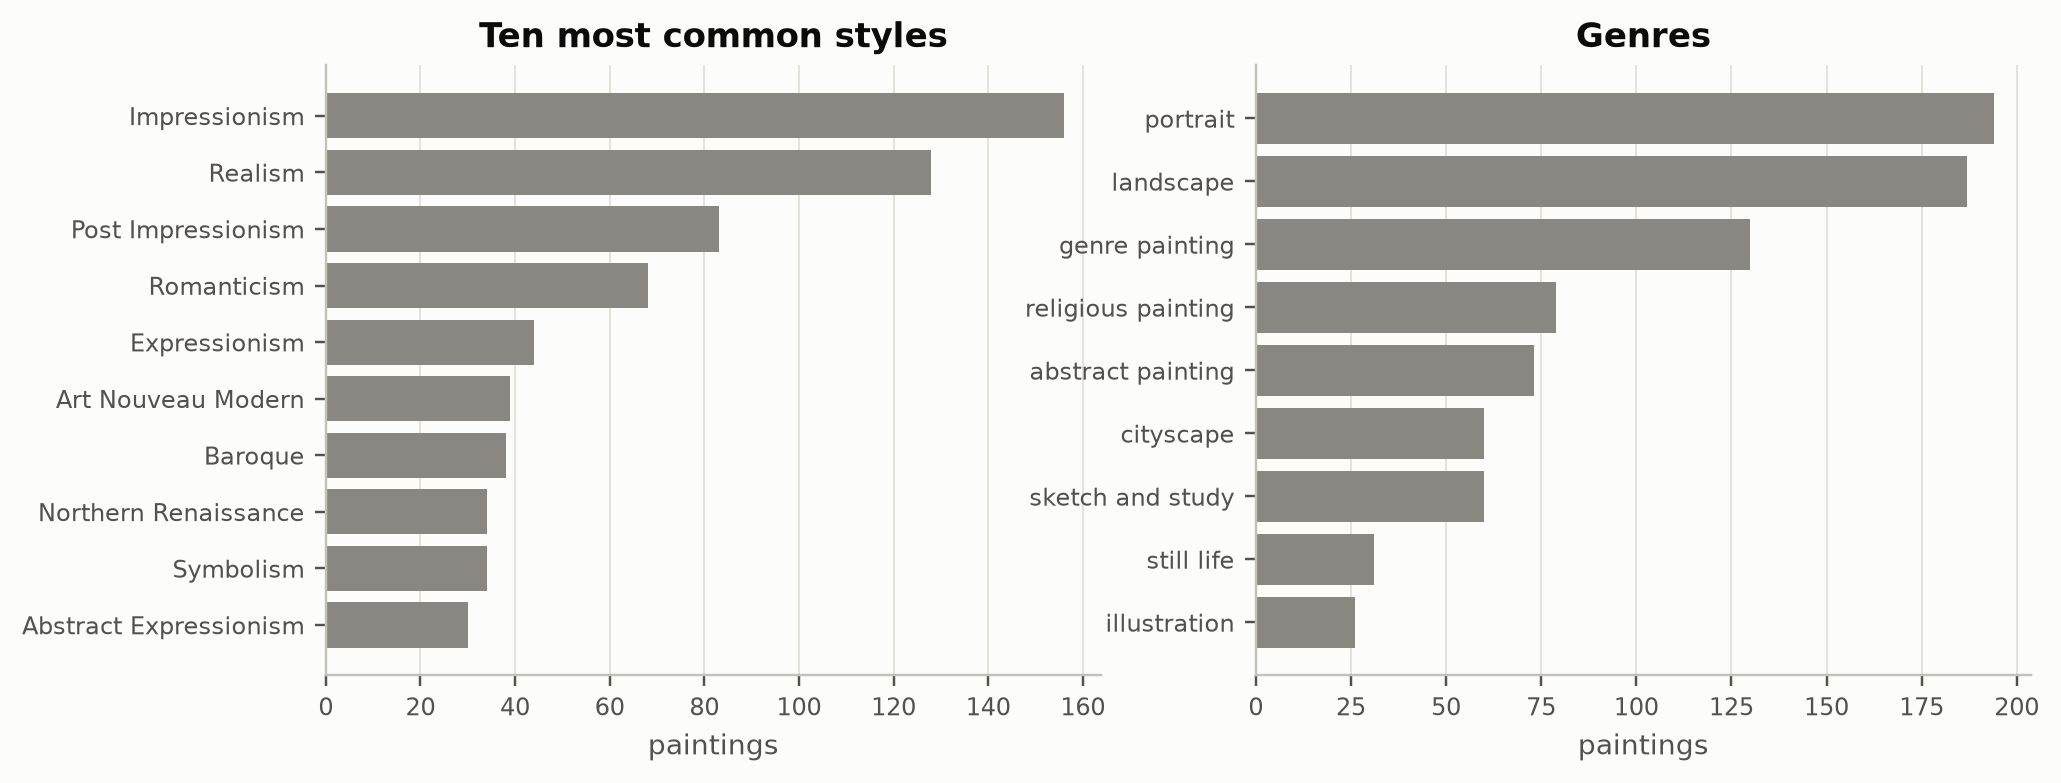

In [4]:
paintings = bal.drop_duplicates("painting")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, title in [
    (axes[0], "art_style", "Ten most common styles"),
    (axes[1], "genre", "Genres"),
]:
    counts = paintings[col].value_counts().head(10)[::-1]
    ax.barh(counts.index.str.replace("_", " "), counts, color=plots.NEUTRAL)
    ax.set_title(title)
    ax.set_xlabel("paintings")
    ax.grid(axis="y", visible=False)
plots.savefig(fig, "00b_paintings")
plt.show()

One painting as it appears in the data, with two of its annotations from each language.

language,emotion,explanation
● english,awe,"I love this, it looks like a 3D Model from some video game. I love the dark colors in it."
● english,contentment,the dark colors on the boat really make it contrast
● arabic,contentment,"ترسي تلك السفينه على اليابسه بعد ان انهكها البحر الشديد من السير فيه(trans.) That ship has come to rest on dry land, worn out by sailing through the rough sea."
● arabic,sadness,قارب متهالك لونه اسود يبدو وكأنه فقد صاحبه يتواجد علي شاطئ البحر(trans.) A battered black boat on the seashore; it looks as if it has lost its owner.
● chinese,contentment,海边的沙滩上搁浅着一艘破旧的船，看起来非常的唯美。(trans.) A battered old boat lies stranded on the beach by the sea; it looks truly beautiful.
● chinese,sadness,岸边破旧的船只，看着很萧条。(trans.) A battered boat on the shore; it looks bleak.

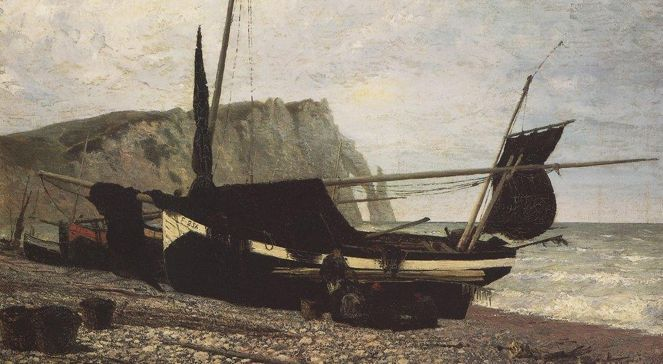

In [5]:
# (original, translation) pairs by Claude Opus 5.5, for reading only
TRANSLATIONS = dict(
    [
        (
            "ترسي تلك السفينه على اليابسه بعد ان انهكها البحر الشديد من السير فيه",
            "That ship has come to rest on dry land, worn out by sailing through the rough sea.",
        ),
        (
            "قارب متهالك لونه اسود يبدو وكأنه فقد صاحبه يتواجد علي شاطئ البحر",
            "A battered black boat on the seashore; it looks as if it has lost its owner.",
        ),
        (
            "海边的沙滩上搁浅着一艘破旧的船，看起来非常的唯美。",
            "A battered old boat lies stranded on the beach by the sea; it looks truly beautiful.",
        ),
        (
            "岸边破旧的船只，看着很萧条。",
            "A battered boat on the shore; it looks bleak.",
        ),
    ]
)

example = bal["painting"].sample(1, random_state=cfg.seed).iloc[0]
rows = bal[bal["painting"] == example].groupby("language").head(2)
rows = rows.set_index("language").loc[LANGS].reset_index()
show.show(
    show.figure(show.thumb(image_path(example), 260), show.title(example), width=380),
    show.annotation_table(rows, translations=TRANSLATIONS),
)

## 1. The obvious model: a concept bottleneck

<div style="border:1.5px solid #d4a27f;background:rgba(212,162,127,0.09);border-radius:6px;padding:10px 16px;margin:6px 0 10px;box-sizing:border-box;max-width:100%">
<div style="font-size:1.05em;line-height:1.5;font-style:italic">“models that we can interact with using high-level concepts”</div>
<div style="opacity:0.75;margin-top:3px;font-size:0.92em">Koh et al., Concept Bottleneck Models (ICML 2020)</div>
</div>

We build the model first and keep questions for later. For each language, a classifier
goes from a painting's concept scores to the emotion people chose, and is scored on
paintings it has never seen.

**Hypothesis.** The bottleneck predicts emotion choices better than knowing each
language's overall habits.

**Method.**

- *Measure:* for each language, a classifier from the painting's concept scores to the
  emotion chosen, scored on paintings it has never seen. First the plain view, as
  ArtELingo reports it: how often the top guess is the emotion the person chose, next to
  always guessing the most common emotion and a naive classifier that ignores language.
  Then the main score: how much of the
  error of a habits-only guess it removes: 0 means no better than knowing each
  language's overall mix, 1 means perfect. We compare it with two references: a black
  box that uses CLIP's raw image embedding instead of named concepts, and what other
  people said about the same painting.
- *If concepts didn't matter:* give each painting a random other painting's concept
  scores and retrain, many times.
- *Reading it:* supported if the bottleneck beats every swapped version.

How the bottleneck works, on made-up numbers: what is in the painting goes in, and each
language's head gives its own emotion mix. On an unseen annotation, the score compares the
bottleneck's error with the error of a habits-only guess.

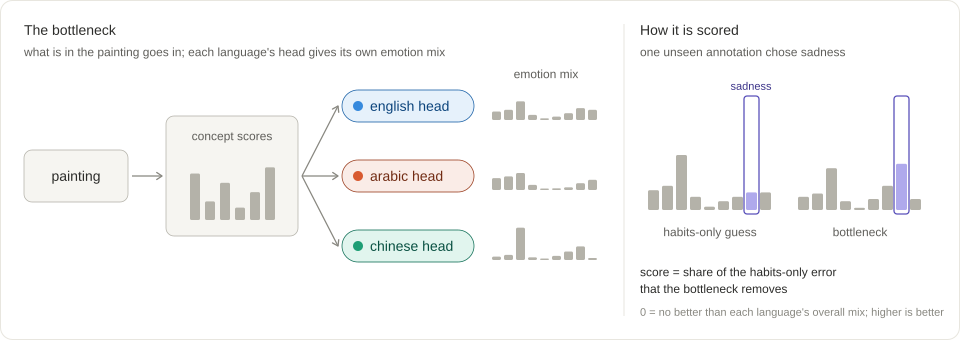

In [6]:
show.method_figure("01_bottleneck")

Embed the images and the concept descriptions with CLIP, and score every painting on
every concept. The concepts are a generic list of about 150 (objects, people, scenes,
colours, light, composition, brushwork), written by Claude Opus 5.5 without emotion
words or anything culture-specific; it uses no labels.

In [7]:
clip = embed.load_clip(cfg.embedding.model, cfg.embedding.pretrained, DEVICE)
emb = cfg.embedding
img_cache = emb.cache_dir / f"images_{emb.model}_{emb.pretrained}.parquet"
img_emb = embed.embed_images(
    painting_images, cfg.data.images_dir, img_cache, clip, cfg.embedding.batch_size, DEVICE
)
concepts = [c for c in cfg.concepts.path.read_text().splitlines() if c.strip()]
template = cfg.concepts.templates["english"]
txt_emb = embed.embed_texts([template.format(c) for c in concepts], clip, DEVICE)
scores = embed.concept_scores(img_emb, txt_emb, concepts)
image_to_painting = dict(zip(painting_images.to_numpy(), painting_images.index, strict=True))
scores.index = scores.index.map(image_to_painting)
print(f"{len(concepts)} concepts scored on {len(scores)} paintings")

152 concepts scored on 840 paintings


Do the concept scores make sense? Three random paintings with their five
highest-scoring concepts.


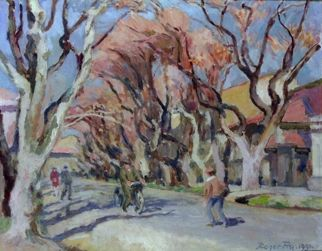
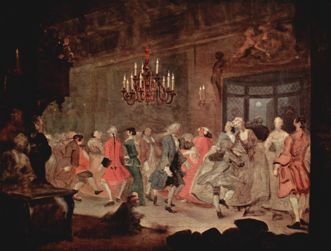
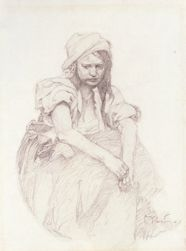

In [8]:
picks = pd.Series(scores.index).sample(3, random_state=cfg.seed)
show.show(
    *[
        show.figure(
            show.thumb(image_path(p), 180),
            f"<b>{show.title(p)}</b><br>" + ", ".join(scores.loc[p].nlargest(5).index),
            width=280,
        )
        for p in picks
    ]
)

Fit the bottleneck, the black box and the other-people reference on unseen paintings.
The habits-only baseline is each language's overall mix of emotions (section 2 shows these
habits in detail).

In [9]:
Cs = cfg.analysis.forward_Cs
habits = cbm.prior_cv(bal, EMOS, cfg.analysis.cv_folds, cfg.seed)
raw_emb = img_emb.copy()
raw_emb.index = raw_emb.index.map(image_to_painting)

fwd_probs, fwd_fits = cbm.forward_cv(bal, scores, EMOS, LANGS, cfg.analysis.cv_folds, Cs, cfg.seed)
box_probs, _ = cbm.forward_cv(bal, raw_emb, EMOS, LANGS, cfg.analysis.cv_folds, Cs, cfg.seed)
people_probs = cbm.other_annotators(bal, EMOS, cfg.analysis.cv_folds, cfg.seed)

forward = pd.DataFrame(
    {
        "bottleneck": cbm.explained(bal, fwd_probs, habits, EMOS),
        "black box": cbm.explained(bal, box_probs, habits, EMOS),
        "other people": cbm.explained(bal, people_probs, habits, EMOS),
    }
).loc[EMOS + ["all emotions"]]
forward.loc[["all emotions"]]

,bottleneck,black box,other people
all emotions,0.051,0.054,0.042


First the plain view: how often is the top guess the emotion the person chose? Next to
the bottleneck: chance, always guessing the most common emotion, a naive classifier that
ignores language (one model for all three), and ArtELingo's majority baseline. That
baseline predicts each annotation with the most common label among the same painting's
annotations in the same language. It reads the answers, so no model that sees only the
painting can beat it: it is the ceiling for this kind of model.

In [10]:
pooled = bal.assign(language="all")
naive_probs, _ = cbm.forward_cv(pooled, scores, EMOS, ["all"], cfg.analysis.cv_folds, Cs, cfg.seed)
most_common = cbm.prior_cv(pooled, EMOS, cfg.analysis.cv_folds, cfg.seed)
top_share = bal.groupby(["painting", "language"])["emotion"].agg(
    lambda s: s.value_counts().iloc[0] / len(s)
)


def accuracy(probs):
    hit = pd.Series(probs.idxmax(axis=1).to_numpy() == bal["emotion"].to_numpy())
    return [*hit.groupby(bal["language"].to_numpy()).mean()[LANGS], hit.mean()]


accuracies = pd.DataFrame(
    {
        "chance": [1 / len(EMOS)] * 4,
        "always the most common emotion": accuracy(most_common),
        "naive classifier (one model)": accuracy(naive_probs),
        "bottleneck (one head per language)": accuracy(fwd_probs),
        "black box": accuracy(box_probs),
        "majority per painting (ceiling)": [
            *top_share.groupby(level="language").mean()[LANGS],
            top_share.mean(),
        ],
    },
    index=LANGS + ["all"],
).T
paper = pd.DataFrame(
    {"english": [0.474, 0.663], "arabic": [0.491, 0.558], "chinese": [0.604, 0.927]},
    index=["majority per painting", "best classifier, reading the explanation (XLM-ACE)"],
)
share_content = (naive_probs.idxmax(axis=1) == "contentment").mean()
print(f"the naive classifier guesses contentment for {share_content:.0%} of annotations")
display(accuracies)
print("ArtELingo paper, Table 5 (their test split of all paintings):")
display(paper)

the naive classifier guesses contentment for 82% of annotations


,english,arabic,chinese,all
chance,0.111,0.111,0.111,0.111
always the most common emotion,0.303,0.304,0.497,0.368
naive classifier (one model),0.331,0.312,0.494,0.379
bottleneck (one head per language),0.341,0.320,0.506,0.389
black box,0.350,0.315,0.505,0.390
majority per painting (ceiling),0.515,0.488,0.624,0.542


ArtELingo paper, Table 5 (their test split of all paintings):


,english,arabic,chinese
majority per painting,0.474,0.491,0.604
"best classifier, reading the explanation (XLM-ACE)",0.663,0.558,0.927


Accuracy per language, with the majority-per-painting ceiling as a black tick.

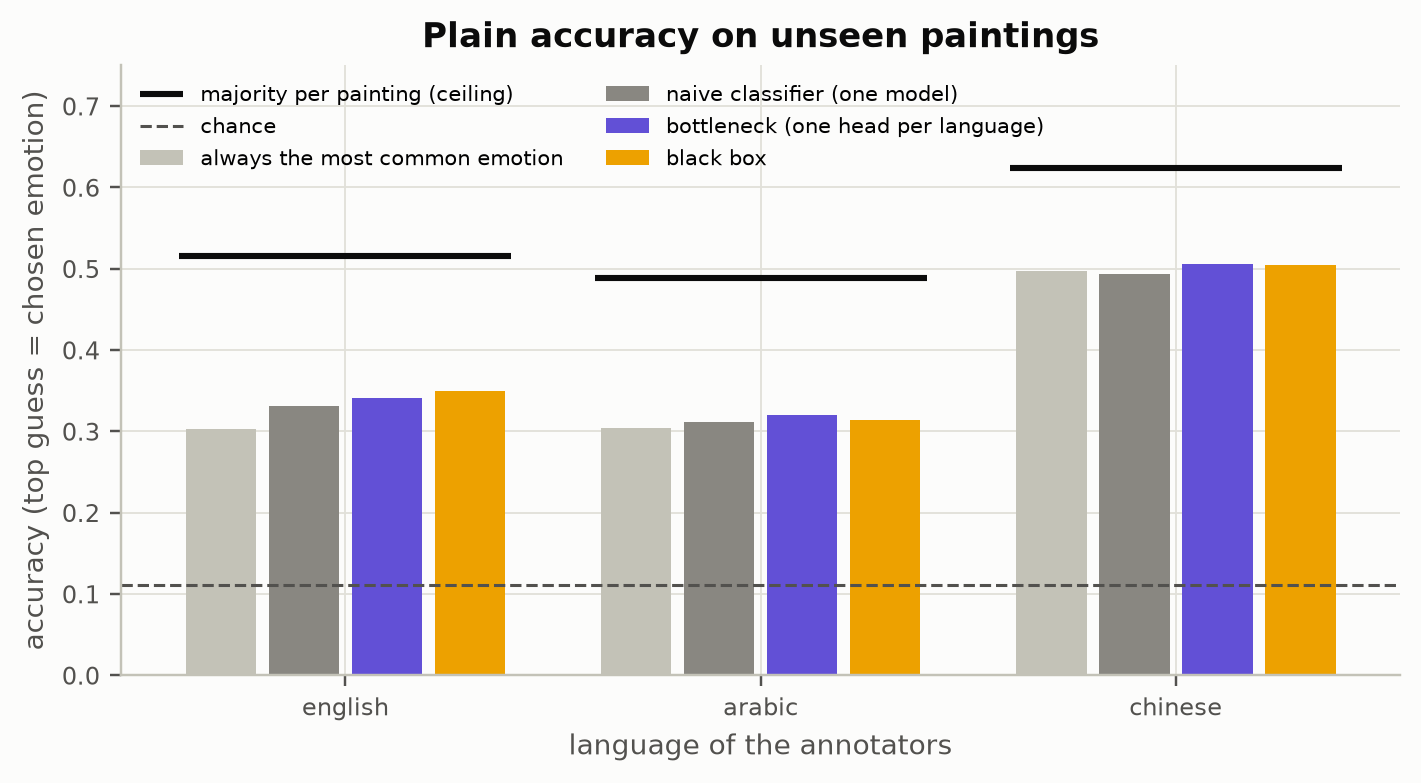

In [11]:
bars = {
    "always the most common emotion": "#c3c2b7",
    "naive classifier (one model)": plots.NEUTRAL,
    "bottleneck (one head per language)": plots.MODEL_COLORS["bottleneck"],
    "black box": plots.MODEL_COLORS["black box"],
}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x_pos, w = np.arange(len(LANGS)), 0.2
for i, (name, color) in enumerate(bars.items()):
    ax.bar(
        x_pos + (i - 1.5) * w, accuracies.loc[name, LANGS], width=w - 0.03, color=color, label=name
    )
ceiling = accuracies.loc["majority per painting (ceiling)", LANGS]
ax.hlines(
    ceiling,
    x_pos - 2 * w,
    x_pos + 2 * w,
    color=plots.INK,
    lw=2,
    label="majority per painting (ceiling)",
)
ax.axhline(1 / len(EMOS), color=plots.INK_2, ls="--", lw=1, label="chance")
ax.set_xticks(x_pos, LANGS)
ax.set_xlabel("language of the annotators")
ax.set_ylabel("accuracy (top guess = chosen emotion)")
ax.set_ylim(0, 0.75)
ax.set_title("Plain accuracy on unseen paintings")
ax.legend(loc="upper left", fontsize=7, ncol=2)
plots.savefig(fig, "01b_accuracy")
plt.show()

The bottleneck against swapped concept scores, and its scores per language.

In [12]:
fixed_C = Counter(m[-1].C for _, _, m in fwd_fits).most_common(1)[0][0]
fwd_swaps = cbm.forward_swap_null(
    bal,
    scores,
    EMOS,
    LANGS,
    cfg.analysis.n_permutations,
    cfg.analysis.cv_folds,
    fixed_C,
    cfg.seed,
)
fwd_real = forward.loc["all emotions", "bottleneck"]
print(
    f"bottleneck: {fwd_real:.3f} | swapped concepts: mean {fwd_swaps.mean():.3f}, max "
    f"{fwd_swaps.max():.3f} | " + analysis.describe_p(fwd_real, fwd_swaps, "swaps")
)
by_language = pd.Series(
    {
        lang: cbm.explained(
            bal, fwd_probs, habits, EMOS, rows=(bal["language"] == lang).to_numpy()
        )["all emotions"]
        for lang in LANGS
    },
    name="bottleneck, by language",
)
by_language

bottleneck: 0.051 | swapped concepts: mean -0.014, max -0.009 | beat all 200 swaps (p < 0.01)


english    0.051
arabic     0.027
chinese    0.078
Name: bottleneck, by language, dtype: float64

One unseen painting: what each language's annotators chose, next to what the bottleneck
predicted for that language.

,chosen,predicted
● english,"contentment ×3, awe ×2","contentment 40%, sadness 25%, awe 11%"
● arabic,"amusement ×2, contentment ×1, sadness ×1, awe ×1","contentment 32%, amusement 26%, awe 17%"
● chinese,"contentment ×3, awe ×1, excitement ×1","contentment 58%, sadness 25%, awe 4%"

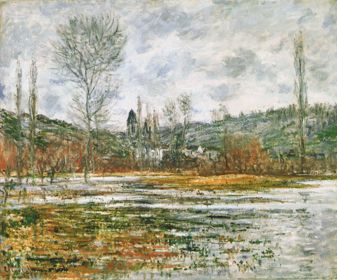

In [13]:
ex = bal["painting"].drop_duplicates().sample(1, random_state=cfg.seed + 4).iloc[0]
show.show(
    show.figure(show.thumb(image_path(ex), 200), show.title(ex), width=320),
    show.prediction_table(bal, fwd_probs, ex, LANGS),
)

<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Supported, but modest.</b> In plain accuracy, the bottleneck's top guess is the chosen
emotion 39% of the time, against 37% for always guessing contentment; the naive classifier
that ignores language guesses contentment for 82% of annotations and lands in between.
Even ArtELingo's majority baseline, which reads the answers off the same painting, gets
only 54% (we reproduce it at 0.52, 0.49 and 0.62 for English, Arabic and Chinese; the paper
reports 0.47, 0.49 and 0.60 on its test split): a painting does not settle one emotion.
ArtELingo's best classifier does much better (0.66, 0.56 and 0.93) because it reads the
explanation, which was written to justify the label.
<br><br>
On the main score, the bottleneck removes about 5.1% of the habits-only
error, while swapped concepts make things worse (beat all 200 swaps, p < 0.01). Named
concepts cost little: a black box on CLIP's raw image embedding removes 5.4%. What other
people said about the same painting removes 4.2%. The bottleneck works best for the
Chinese annotators (7.8%) and least for the Arabic annotators (2.7%).

</div>

**What this raises**

- Is 5% good? How much could any model get from the painting? (section 6)
- Why does it differ so much by language? (sections 2 to 5)
- Would another encoder, or concepts in each language, do better? (sections 7 and 8)
- Do the concepts behave like concepts: does correcting them help? (section 9)

The questions the rest of the notebook asks about this model. Each box is one question;
the numbers are the sections that answer it.

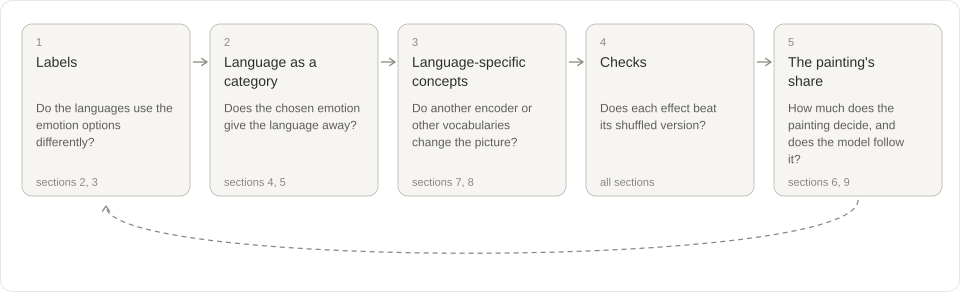

In [14]:
show.method_figure("02_argument_chain")

# Part I · Where does language show up?

## 2. Do people disagree more across languages than within one?

<div style="border:1.5px solid #d4a27f;background:rgba(212,162,127,0.09);border-radius:6px;padding:10px 16px;margin:6px 0 10px;box-sizing:border-box;max-width:100%">
<div style="font-size:1.05em;line-height:1.5;font-style:italic">“joint knowledge of conventional means of doing things”</div>
<div style="opacity:0.75;margin-top:3px;font-size:0.92em">Becker, Art Worlds (1982), defining an art world</div>
</div>

**Hypothesis.** People writing in different languages disagree more about a specific
painting than people writing in the same language, beyond what each language's overall
label habits would produce.

**Method.**

- *Measure:* for each painting, draw small random groups of annotators from each
  language and compare the mix of emotions they chose. Comparing two groups from the
  same language gives disagreement *within* a language; comparing groups from two
  languages gives disagreement *across* languages. What we care about is the gap.
- *If language didn't matter:* shuffle the language tags within each painting and
  recompute the gap, many times.
- *If only label habits mattered:* within each language, move the labels across
  paintings at random. Each language keeps its overall mix of emotions, but labels lose
  any link to a particular painting. The gap that remains is what habits alone produce.
- *Reading it:* supported if the real gap is clearly larger than both. The real gap
  minus the habits-only gap is the part that is about specific paintings.

How the test works, on made-up labels. Each square is one annotator's label. Left: the
real labels, with one comparison within English and one across English and Chinese.
Middle and right: what each shuffle does to the same labels.

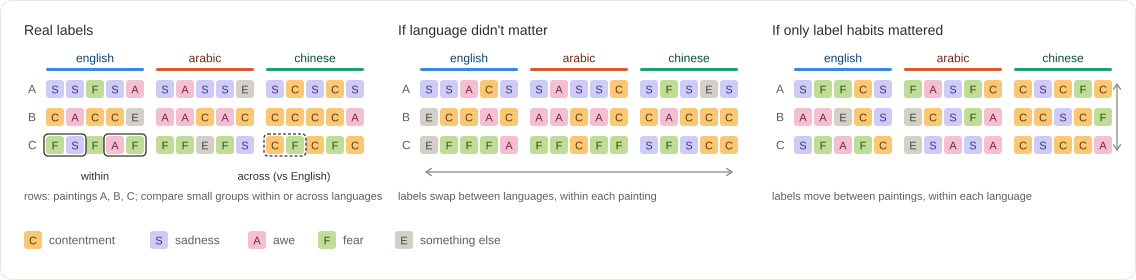

In [15]:
show.method_figure("03_shuffle_tests")

What this looks like on two paintings: the one where the languages disagree most, and
one where nearly everyone agrees. Compare how labels spread inside each language with
how they differ between languages.

● english,"contentment ×3, sadness ×2"
● arabic,amusement ×5
● chinese,contentment ×5
● english,"sadness ×4, disgust ×1"
● arabic,sadness ×5
● chinese,"sadness ×4, fear ×1"

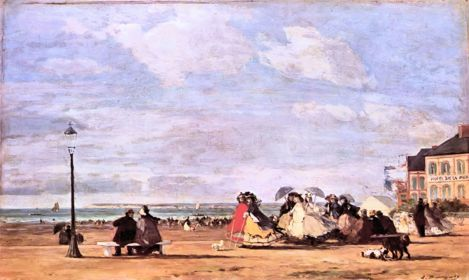
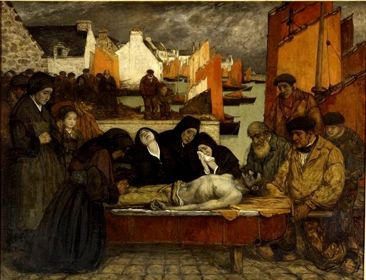

In [16]:
within, cross, pairs = analysis.split_half_divergence(
    labels, len(EMOS), cfg.analysis.n_bootstrap, cfg.seed
)
paintings = bal["painting"].unique()  # same order as `labels`
gap_by_painting = pd.Series(cross.mean(axis=1) - within.mean(axis=1), index=paintings)
top_share = pd.Series([np.bincount(lab.ravel()).max() for lab in labels], index=paintings)

examples = {
    "languages disagree most": gap_by_painting.idxmax(),
    "nearly everyone agrees": top_share.idxmax(),
}
show.show(
    *[
        show.figure(
            show.thumb(image_path(p), 200),
            f"<i>{note}</i><br>{show.title(p)}" + show.emotion_counts(bal, p, LANGS),
            width=420,
        )
        for note, p in examples.items()
    ]
)

First, each language's overall habits: how often it picks each emotion. All three
languages saw the same paintings, so any difference here comes from the annotators,
not from the paintings.

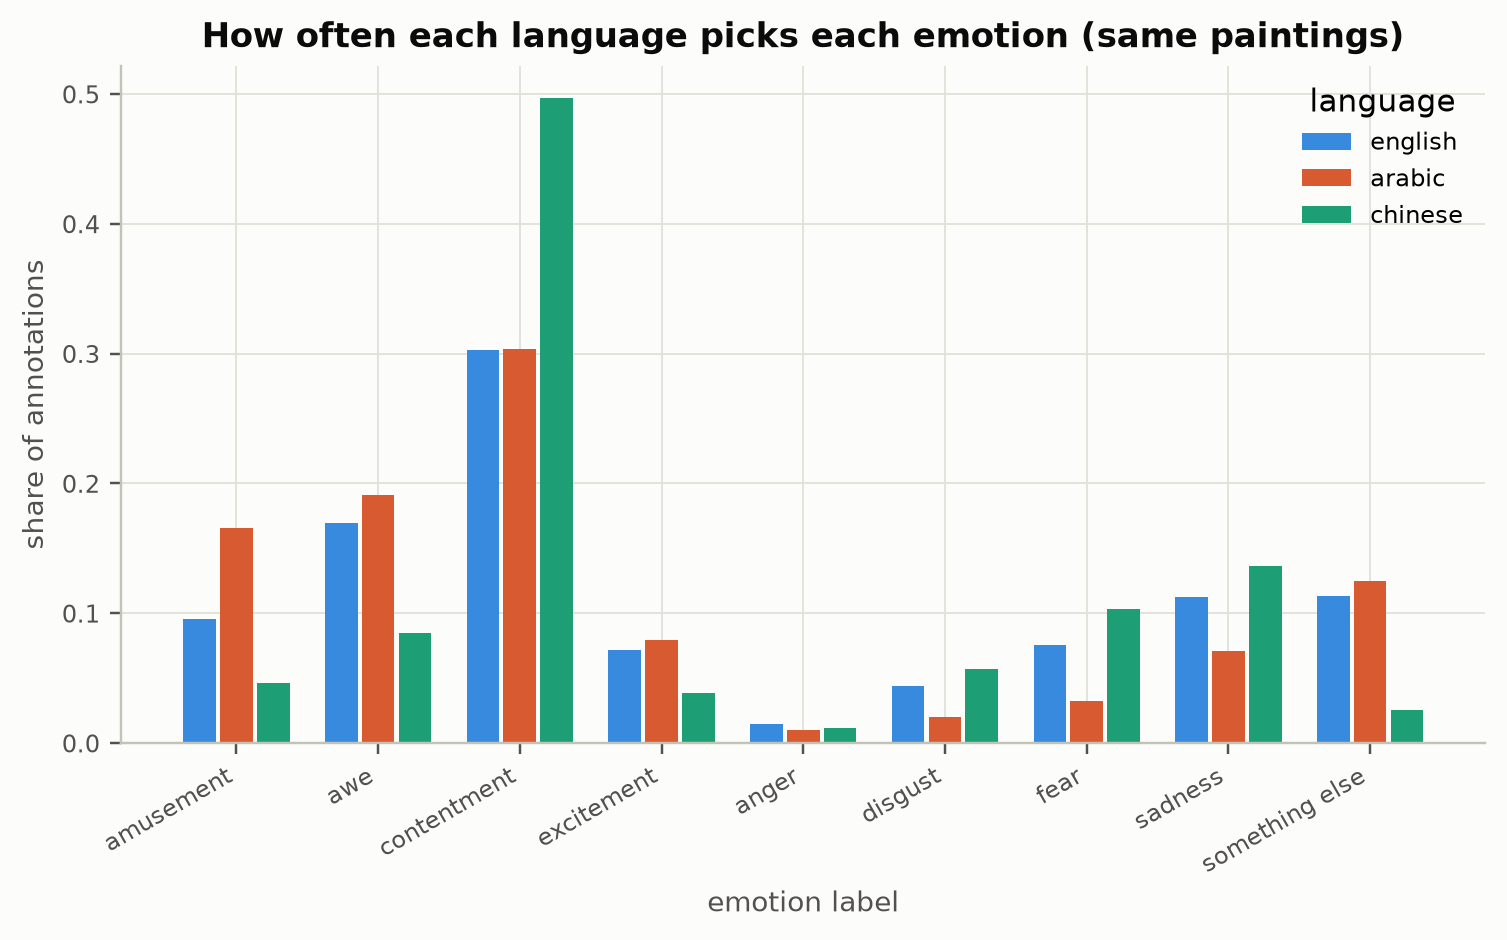

emotion,amusement,awe,contentment,excitement,anger,disgust,fear,sadness,something else
language,,,,,,,,,
english,0.095,0.170,0.303,0.072,0.015,0.044,0.076,0.112,0.114
arabic,0.166,0.191,0.304,0.079,0.010,0.020,0.033,0.071,0.125
chinese,0.046,0.085,0.497,0.039,0.012,0.057,0.103,0.136,0.025


In [17]:
priors = pd.crosstab(bal["emotion"], bal["language"], normalize="columns").loc[EMOS, LANGS]

fig, ax = plt.subplots(figsize=(8, 4))
x, w = np.arange(len(EMOS)), 0.26
for i, lang in enumerate(LANGS):
    ax.bar(x + (i - 1) * w, priors[lang], width=w - 0.03, color=plots.LANG_COLORS[lang], label=lang)
ax.set_xticks(x, EMOS, rotation=30, ha="right")
ax.set_ylabel("share of annotations")
ax.set_xlabel("emotion label")
ax.set_title("How often each language picks each emotion (same paintings)")
ax.legend(title="language")
plots.savefig(fig, "02b_emotion_priors")
plt.show()
priors.T

Disagreement within and across languages, the gap between them, and the gaps under the
two shuffles.

In [18]:
gap_real = cross.mean() - within.mean()
n_shuffles, n_draws = cfg.analysis.n_permutations, cfg.analysis.n_bootstrap
gap_shuffled, _ = analysis.divergence_gap_null(labels, len(EMOS), n_shuffles, n_draws, cfg.seed)
gap_habits, within_habits = analysis.divergence_gap_null(
    labels, len(EMOS), n_shuffles, n_draws, cfg.seed, shuffle="language"
)

print(f"real gap (across - within):       {gap_real:.3f}")
print(
    f"languages shuffled:               mean {gap_shuffled.mean():.3f}; real gap "
    + analysis.describe_p(gap_real, gap_shuffled)
)
print(
    f"label habits only:                mean {gap_habits.mean():.3f}; real gap "
    + analysis.describe_p(gap_real, gap_habits)
)
print(f"painting-specific part:           {gap_real - gap_habits.mean():.3f}")
print(f"paintings where across > within:  {(cross.mean(axis=1) > within.mean(axis=1)).mean():.0%}")

div_table = pd.DataFrame(
    {
        "real": [within[:, i].mean() for i in range(len(LANGS))]
        + [cross[:, k].mean() for k in range(len(pairs))],
        "label habits only": list(within_habits.mean(axis=0)) + [np.nan] * len(pairs),
    },
    index=[f"within {lang}" for lang in LANGS]
    + [f"across {LANGS[i]}-{LANGS[j]}" for i, j in pairs],
)
div_table

real gap (across - within):       0.081
languages shuffled:               mean -0.000; real gap beat all 200 shuffles (p < 0.01)
label habits only:                mean 0.037; real gap beat all 200 shuffles (p < 0.01)
painting-specific part:           0.043
paintings where across > within:  70%


,real,label habits only
within english,0.582,0.708
within arabic,0.610,0.680
within chinese,0.436,0.561
across english-arabic,0.656,NaN
across english-chinese,0.583,NaN
across arabic-chinese,0.632,NaN


Left: average disagreement for each comparison. Right: the real gap against the gaps
under both shuffles.

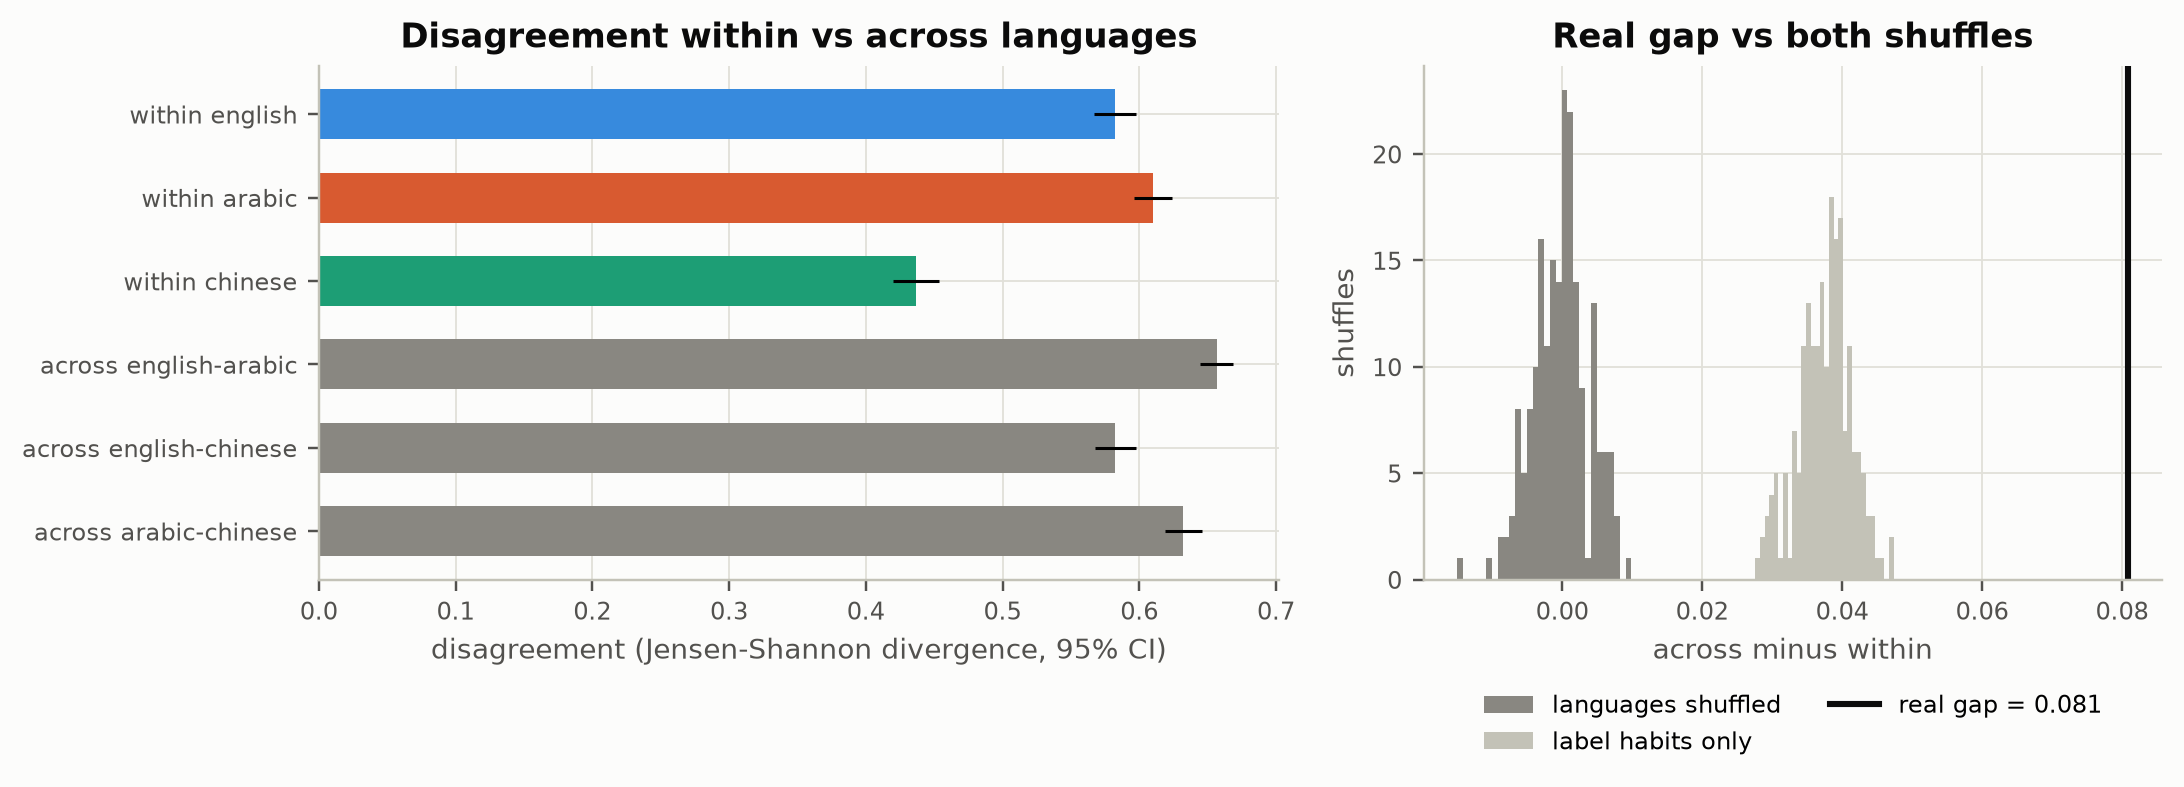

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})

names = list(div_table.index)
vals = div_table["real"].to_numpy()
per_painting = [within[:, i] for i in range(len(LANGS))] + [cross[:, k] for k in range(len(pairs))]
se = np.array([v.std(ddof=1) / np.sqrt(len(v)) for v in per_painting])
colors = [plots.LANG_COLORS[lang] for lang in LANGS] + [plots.NEUTRAL] * len(pairs)
ax1.barh(names, vals, xerr=1.96 * se, color=colors, height=0.6, error_kw={"lw": 1})
ax1.invert_yaxis()
ax1.set_xlabel("disagreement (Jensen-Shannon divergence, 95% CI)")
ax1.set_title("Disagreement within vs across languages")

ax2.hist(gap_shuffled, bins=30, color=plots.NEUTRAL, label="languages shuffled")
ax2.hist(gap_habits, bins=30, color="#c3c2b7", label="label habits only")
ax2.axvline(gap_real, color=plots.INK, lw=2, label=f"real gap = {gap_real:.3f}")
ax2.set_xlabel("across minus within")
ax2.set_ylabel("shuffles")
ax2.set_title("Real gap vs both shuffles")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
fig.tight_layout()
plots.savefig(fig, "02c_divergence_gap")
plt.show()

<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Supported, but about half of the gap is label habits.</b> People writing in
different languages disagree more about a painting than people writing in the same
language: the gap is 0.081, and shuffling languages never gets close (beat all 200
shuffles, p < 0.01). Label habits alone produce a gap of about 0.037, so about
0.043, roughly half, is about specific paintings. That part is real too: the
real gap beat all 200 habits-only shuffles (p < 0.01).

The habits themselves are easy to see. Chinese annotators pick contentment about half
the time and almost never "something else"; Arabic annotators lean more on amusement and
awe. Chinese annotators also agree with each other the most, but they still agree the most
when their labels are shuffled across paintings, which shows their extra agreement comes
from how concentrated their labels are, not from the paintings.

</div>

## 3. What goes into "something else" in each language?

<div style="border:1.5px solid #d4a27f;background:rgba(212,162,127,0.09);border-radius:6px;padding:10px 16px;margin:6px 0 10px;box-sizing:border-box;max-width:100%">
<div style="font-size:1.05em;line-height:1.5;font-style:italic">“Residual categories are those which cannot be formally represented within a given classification system.”</div>
<div style="opacity:0.75;margin-top:3px;font-size:0.92em">Star &amp; Bowker, “Enacting Silence” (Ethics and Information Technology, 2007)</div>
</div>

Every annotator could pick "something else" instead of one of the eight named emotions.
Section 2 showed that Chinese annotators almost never do. Here we look at how often each
language uses the option, and at what people write when they pick it.

**Hypothesis.** The languages use the catch-all option at different rates.

**Method.**

- *Measure:* the share of "something else" in each language, and a few random
  explanations given with it.
- *If language didn't matter:* shuffle the language tags within each painting and
  recompute the shares, many times.
- *Reading it:* supported if the real shares fall outside the shuffled range. The
  explanations only show what the option is used for; we do not model them.

How the test works, on made-up labels: count how often each language uses "something
else", then shuffle the languages within each painting and count again.

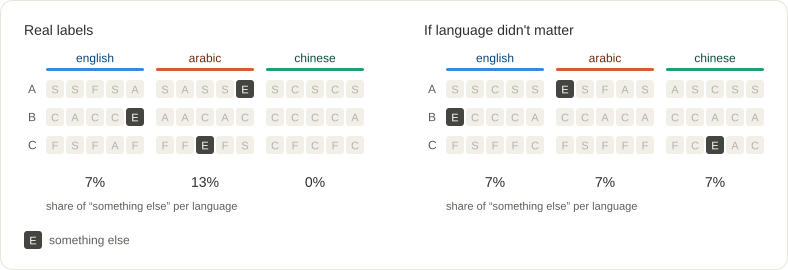

In [20]:
show.method_figure("04_something_else")

How often each language picks "something else", next to the range under shuffling.

In [21]:
is_other = bal["emotion"] == "something else"
rng = np.random.default_rng(cfg.seed)
shuffled_share = pd.DataFrame(
    [
        is_other.groupby(
            analysis.shuffle_labels_within(
                bal["language"].to_numpy(), bal["painting"].to_numpy(), rng
            )
        ).mean()
        for _ in range(cfg.analysis.n_permutations)
    ]
)
other_share = pd.DataFrame(
    {
        "share": is_other.groupby(bal["language"]).mean(),
        "shuffled min": shuffled_share.min(),
        "shuffled max": shuffled_share.max(),
    }
).loc[LANGS]
other_share

,share,shuffled min,shuffled max
english,0.114,0.079,0.095
arabic,0.125,0.077,0.097
chinese,0.025,0.077,0.096


Three random "something else" explanations per language.


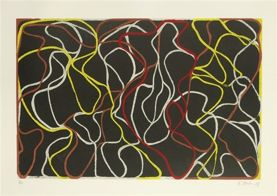
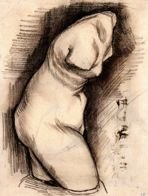
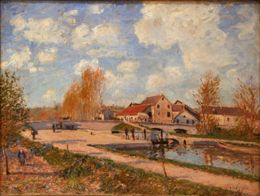


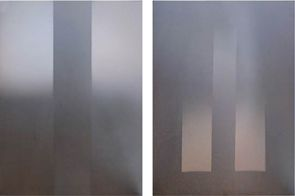
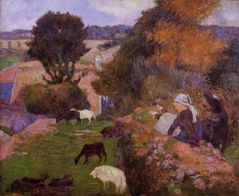
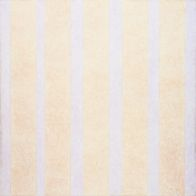


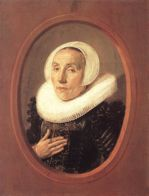
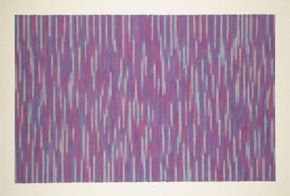
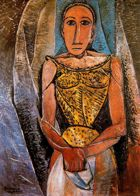

In [22]:
# (original, translation) pairs by Claude Opus 5.5, for reading only
OTHER_TRANSLATIONS = dict(
    [
        (
            "فن تشكيلي يتمثل في تداخل الخطوط بالوان واضاءات مختلفه",
            "Visual art made of overlapping lines in different colours and lighting.",
        ),
        (
            "تبدو انها سيدة ترعي بعض الأغنام تجلس تحت شجرة تستريح من عناء الطريق وتستمتع "
            "بالخضرة والمنظر الخلاب",
            "It looks like a woman tending some sheep, sitting under a tree to rest from the "
            "road and enjoying the greenery and the beautiful view.",
        ),
        (
            "حائط ملون بالأصفر ،وخط أبيض رفيع لقد شعرت بالراحة عندما نظرت إليها.",
            "A wall painted yellow, and a thin white line. I felt at ease when I looked at it.",
        ),
        (
            "王后身穿华服，手放在胸前，非常端庄，令人敬佩。",
            "The queen wears splendid clothes, her hand on her chest; very dignified, admirable.",
        ),
        (
            "画面是一片紫色，有蓝色白色的竖条纹，看起来没什么。",
            "The picture is a field of purple with blue and white vertical stripes; it doesn't "
            "look like much.",
        ),
        (
            "画中女人略显紧张，姿态僵硬，让人觉得比较拘谨。",
            "The woman in the painting looks a little tense and stiff; it feels rather restrained.",
        ),
    ]
)

other_examples = bal[is_other].groupby("language").sample(3, random_state=cfg.seed)
for lang in LANGS:
    show.show(
        *[
            show.figure(
                show.thumb(image_path(r.painting), 140),
                show.lang_label(lang) + show.explanation(r.caption, OTHER_TRANSLATIONS),
                width=280,
            )
            for r in other_examples[other_examples["language"] == lang].itertuples()
        ]
    )

<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Supported.</b> Chinese annotators pick "something else" for about 2.5% of
annotations, against about 11% for English and 12.5% for Arabic, all far outside the
shuffled range. The explanations range from plain descriptions and boredom to reactions
that sound close to the named emotions, such as calm enjoyment or admiration. Because all
three languages saw the same paintings, the paintings cannot explain the difference in
rates. What can, we cannot yet separate: how the option was worded or translated in each
language's interface, or the habits of each language's annotators.

</div>

## 4. Can we tell someone's language from the painting and the emotion they chose?

<div style="border:1.5px solid #d4a27f;background:rgba(212,162,127,0.09);border-radius:6px;padding:10px 16px;margin:6px 0 10px;box-sizing:border-box;max-width:100%">
<div style="font-size:1.05em;line-height:1.5;font-style:italic">“Taste classifies, and it classifies the classifier”</div>
<div style="opacity:0.75;margin-top:3px;font-size:0.92em">Bourdieu, Distinction (1984)</div>
</div>

This turns the usual concept bottleneck around. Instead of predicting the emotion, we
predict the one thing in the data that is not a judgement: which language the
annotator wrote in.

**Hypothesis.** The emotion an annotator chose, alone or together with what is in the
painting, gives their language away.

**Method.**

- *Measure:* train a simple classifier (logistic regression) to predict language, and
  score it on paintings it has never seen. We try four kinds of input:
  - **concepts**: what is in the painting. CLIP scores how strongly the painting shows
    each of a list of plain visual concepts (a person, the sea, warm colours, visible
    brushstrokes…). Many concepts move together (a portrait scores high on "a face" and
    "a person" alike), so we summarise them into a handful of broad visual dimensions.
  - **emotion**: the label the annotator chose
  - **both**: concepts and emotion side by side
  - **interaction**: emotion combined with each visual dimension, such as "fear, on a
    painting with a lot of sea"
- *If language didn't matter:* shuffle the language tags within each painting and
  retrain, many times.
- *Reading it:* supported if the scores clearly beat their shuffled versions. Whether
  the painting adds anything beyond the emotion is the question of section 5.

Concepts alone cannot work here, by design: every language saw the same paintings
equally often. We keep that input as a check that nothing leaks, and it should land
exactly on chance. The concept list is deliberately generic, with no emotion words
and nothing culture-specific, which makes it a label-free starting point.

How the test works: what the classifier gets for one annotation, and why concepts alone
cannot work when every language saw the same paintings equally often.

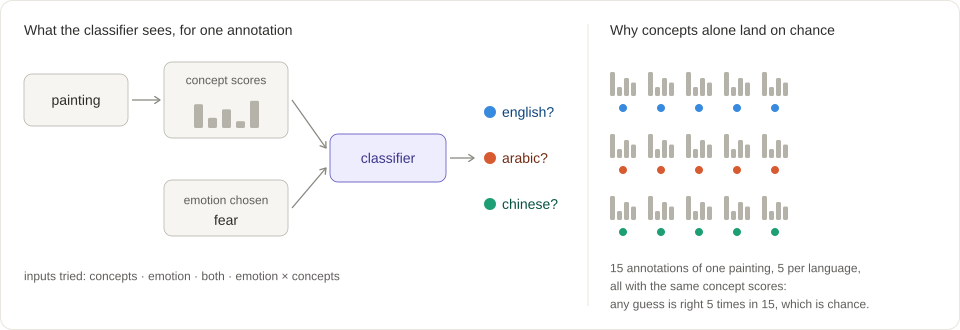

In [23]:
show.method_figure("05_classifier_input")

Summarise the concept scores into broad visual dimensions. Each row shows the concepts
at the two ends of one dimension, which is how to read the dimension names (D1, D2, …)
in the rest of the notebook.

In [24]:
components, loadings = analysis.concept_components(
    scores, cfg.analysis.n_concept_components, cfg.seed
)
pd.set_option("display.max_colwidth", 90)
analysis.describe_components(loadings)

,high,low
D1,"low contrast, thin washes of colour, an asymmetrical composition, a bottle","a face, dots of paint, a line drawing, a dress"
D2,"a person, a portrait composition, a face, a book","a valley, a landscape composition, a hill, a lake"
D3,"empty space, dots of paint, organic shapes, curved lines","a market, daytime scene, a group of people, a wide panoramic view"
D4,"geometric shapes, a symmetrical composition, a crowded scene, a market","a face, green, pink, a person"
D5,"a ship, the sea, the moon, an island","saturated colours, warm colours, a street, cool colours"
D6,"a forest, a meadow, a tree, grass","a harbour, a city, a building, sunset light"
D7,"a sketch, a line drawing, grey, monochrome palette","gold, cool colours, geometric shapes, a symmetrical composition"
D8,"dim light, candlelight, loose rough handling, an abstract composition","dots of paint, a line drawing, fine detail, a grid pattern"
D9,"ice, dots of paint, flowers, snow","vertical lines, a symmetrical composition, a realistic depiction, strong perspective d..."
D10,"a boat, a harbour, curved lines, a beach","silver, dim light, backlighting, a forest"


One dimension in pictures: the paintings at the high end (top row) and the low end
(bottom row) of D2.


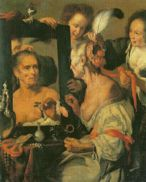
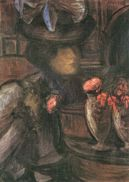
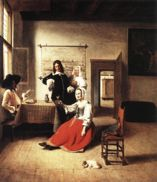
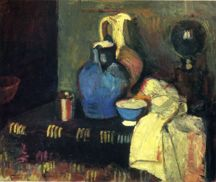
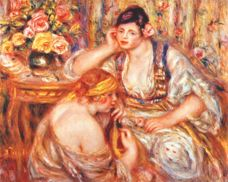


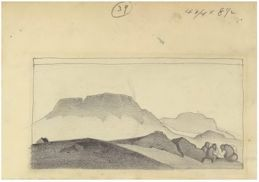
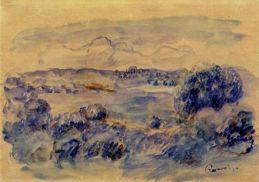
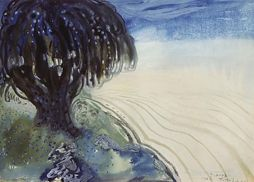
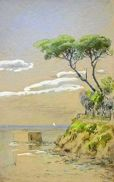
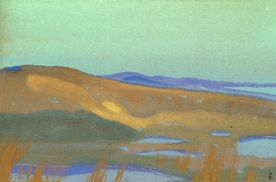

In [25]:
dim = "D2"
for end, idx in [
    ("high", components[dim].nlargest(5).index),
    ("low", components[dim].nsmallest(5).index),
]:
    show.show(*[show.figure(show.thumb(image_path(p), 130), f"{end} {dim}") for p in idx])

What the classifier actually gets for one annotation: the emotion that was chosen and
where the painting sits on each visual dimension. From that, it has to guess the
language.


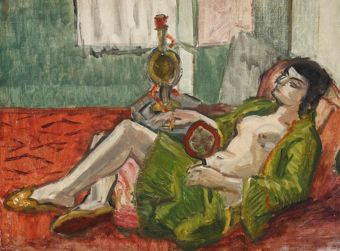

In [26]:
ex = bal.sample(1, random_state=cfg.seed + 1).iloc[0]
dims = ", ".join(f"{d} {v:+.1f}" for d, v in components.loc[ex["painting"]].items())
show.show(
    show.figure(show.thumb(image_path(ex["painting"]), 180), show.title(ex["painting"]), width=280),
    f"<div style='max-width:440px'><b>emotion:</b> {ex['emotion']}<br>"
    f"<b>visual dimensions:</b> {dims}<br><br>"
    f"<b>which language?</b> Answer: {show.lang_label(ex['language'])}</div>",
)

Train and score the classifier on each kind of input, with its shuffled baseline.

In [27]:
FEATURE_SETS = ["concepts", "emotion", "both", "interaction"]
y, groups = bal["language"].to_numpy(), bal["painting"].to_numpy()

rows, cbm_nulls = [], {}
for kind in FEATURE_SETS:
    X, _ = analysis.make_features(bal, kind, EMOS, components)
    real = analysis.cv_balanced_accuracy(
        X, y, groups, cfg.analysis.cv_folds, cfg.analysis.logreg_C, cfg.seed
    )
    row = {"input": kind, "n features": X.shape[1], "balanced acc": real}
    if kind != "concepts":  # exactly chance by construction; shuffling adds nothing
        cbm_nulls[kind] = analysis.permutation_null(
            X,
            y,
            groups,
            cfg.analysis.n_permutations,
            cfg.analysis.cv_folds,
            cfg.analysis.logreg_C,
            cfg.seed,
        )
        row |= {
            "shuffled mean": cbm_nulls[kind].mean(),
            "shuffled max": cbm_nulls[kind].max(),
            "vs shuffles": analysis.describe_p(real, cbm_nulls[kind]),
        }
    rows.append(row)
inverted = pd.DataFrame(rows).set_index("input")
print("chance (always guessing one language): 0.333")
inverted

chance (always guessing one language): 0.333


,n features,balanced acc,shuffled mean,shuffled max,vs shuffles
input,,,,,
concepts,10,0.333,NaN,NaN,NaN
emotion,9,0.457,0.333,0.347,beat all 200 shuffles (p < 0.01)
both,19,0.455,0.333,0.347,beat all 200 shuffles (p < 0.01)
interaction,99,0.464,0.333,0.345,beat all 200 shuffles (p < 0.01)


Real scores against the range of shuffled scores and chance.

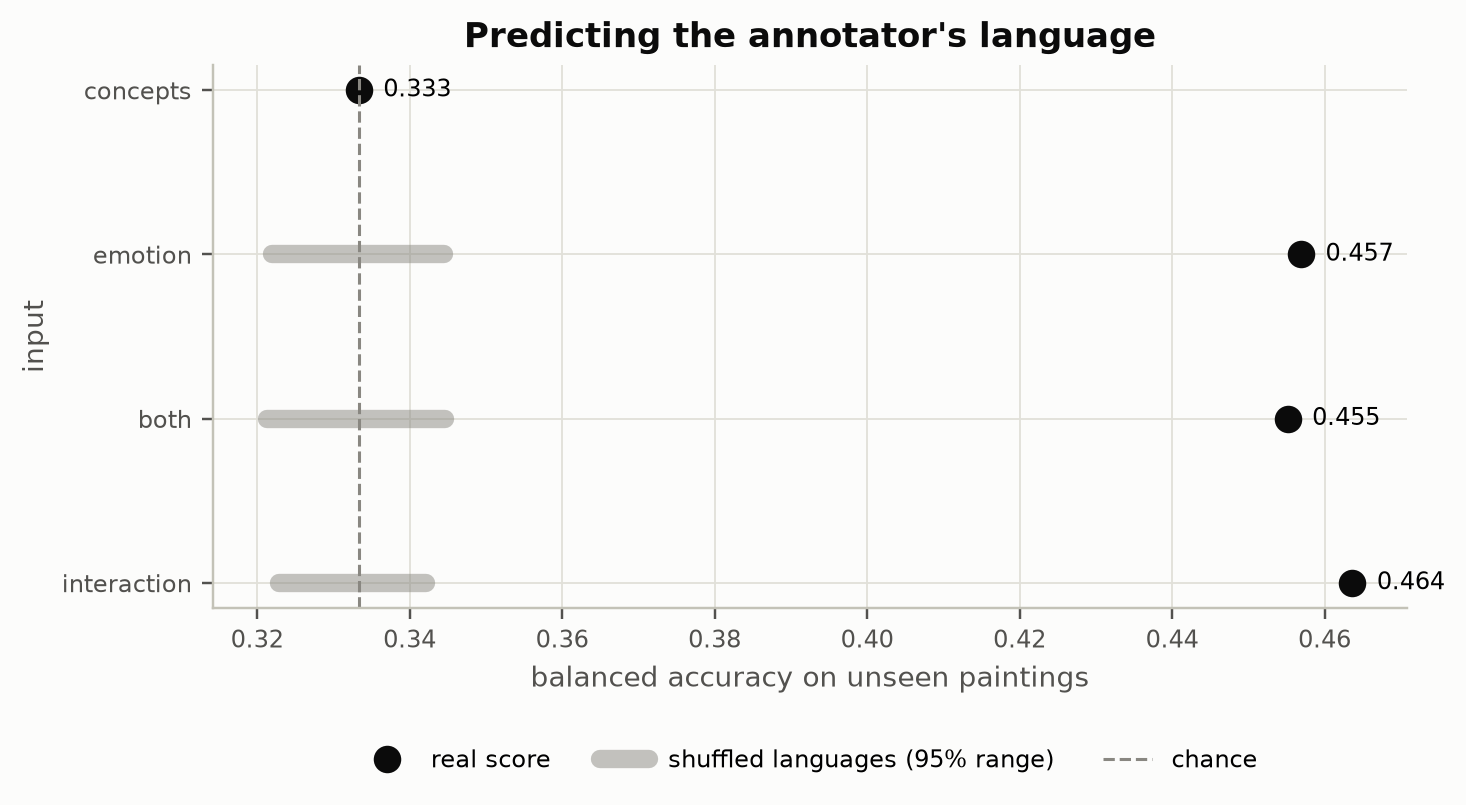

In [28]:
def plot_cbm(table, nulls, title, ax):
    for i, kind in enumerate(table.index):
        if kind in nulls:
            lo, hi = np.quantile(nulls[kind], [0.025, 0.975])
            ax.plot(
                [lo, hi],
                [i, i],
                color=plots.NEUTRAL,
                lw=6,
                alpha=0.5,
                solid_capstyle="round",
                label="shuffled languages (95% range)" if i == 1 else None,
            )
        ax.plot(
            table.loc[kind, "balanced acc"],
            i,
            "o",
            color=plots.INK,
            ms=8,
            label="real score" if i == 0 else None,
        )
        ax.annotate(
            f"{table.loc[kind, 'balanced acc']:.3f}",
            (table.loc[kind, "balanced acc"], i),
            xytext=(8, 0),
            textcoords="offset points",
            va="center",
            fontsize=8,
        )
    ax.axvline(1 / 3, color=plots.NEUTRAL, ls="--", lw=1, label="chance")
    ax.set_yticks(range(len(table)), table.index)
    ax.invert_yaxis()
    ax.set_xlabel("balanced accuracy on unseen paintings")
    ax.set_ylabel("input")
    ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)


fig, ax = plt.subplots(figsize=(7, 3.2))
plot_cbm(inverted, cbm_nulls, "Predicting the annotator's language", ax)
plots.savefig(fig, "04b_language_classifier")
plt.show()

What the model leans on: for each language, the combinations of visual dimension and
emotion that push its prediction toward that language the most (read the dimensions
with the table above). These describe this model on this sample. They are not facts
about cultures.

In [29]:
X_int, int_names = analysis.make_features(bal, "interaction", EMOS, components)
model = analysis.logreg(cfg.analysis.logreg_C).fit(X_int, y)
coef = pd.DataFrame(model[-1].coef_, index=model[-1].classes_, columns=int_names)
coef = coef.loc[:, [n for n in int_names if " | " in n]]  # concept x emotion terms only
top = pd.DataFrame({lang: coef.loc[lang].nlargest(8).index for lang in LANGS})
top.index = range(1, 9)
top

,english,arabic,chinese
1,D2 | amusement,D1 | amusement,D2 | amusement
2,D1 | anger,D2 | sadness,D3 | awe
3,D1 | contentment,D2 | contentment,D5 | amusement
4,D3 | excitement,D5 | excitement,D3 | amusement
5,D2 | awe,D9 | amusement,D7 | amusement
6,D4 | something else,D8 | sadness,D4 | awe
7,D3 | amusement,D7 | awe,D4 | amusement
8,D8 | excitement,D8 | awe,D10 | amusement


<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Supported.</b> The chosen emotion alone guesses the annotator's language at 0.457,
against 0.333 for chance and at most 0.347 for shuffled languages (beat all 200
shuffles, p < 0.01). Adding what is in the
painting barely moves it (0.464 for the interaction). Concepts alone sit exactly on
chance, as they should, so nothing leaks.

</div>

## 5. Does what is in the painting add anything beyond label habits?

<div style="border:1.5px solid #d4a27f;background:rgba(212,162,127,0.09);border-radius:6px;padding:10px 16px;margin:6px 0 10px;box-sizing:border-box;max-width:100%">
<div style="font-size:1.05em;line-height:1.5;font-style:italic">Would a journal publish “an article liberally salted with nonsense if (a) it sounded good”?</div>
<div style="opacity:0.75;margin-top:3px;font-size:0.92em">Sokal, “A Physicist Experiments With Cultural Studies” (Lingua Franca, 1996)</div>
</div>

Section 2 showed that each language favours some emotions over others. The emotion-only
classifier in section 4 already knows these habits completely: if one language picks
contentment more often, it guesses that language from contentment. So the real question
is whether knowing what is in the painting adds anything on top.

**Hypothesis.** Painting content improves the language guess beyond what the chosen
emotion alone gives: languages attach different emotions to the same visual content.

**Method.**

- *Measure:* the score of the interaction classifier from section 4 (emotion combined with
  the visual dimensions).
- *If painting content didn't matter:* keep every annotation's language and emotion as
  they are, but give each painting the visual profile of a random other painting, and
  retrain, many times. Label habits stay intact; only the link to what is actually in
  the painting is broken.
- *Reading it:* supported if the real score beats every swapped score.

How the swap works, on made-up annotations: each annotation keeps its language and
emotion; only the concept profile it is paired with comes from another painting.

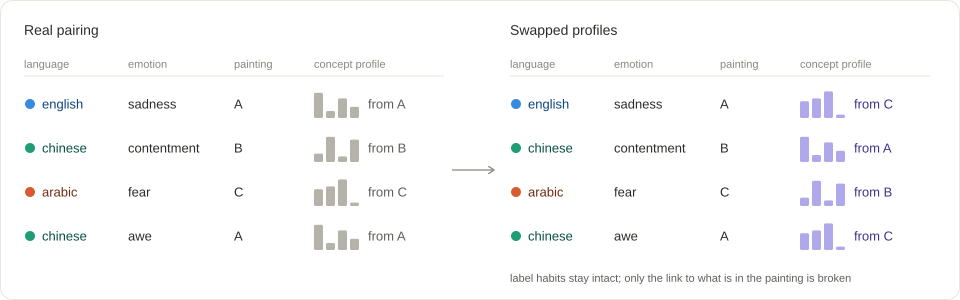

In [30]:
show.method_figure("06_swap_test")

The swap on one annotation: the real pairing, and the same annotation after it has been
handed a random other painting's visual profile.


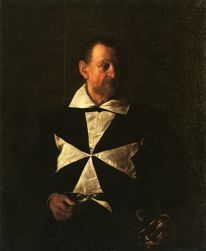
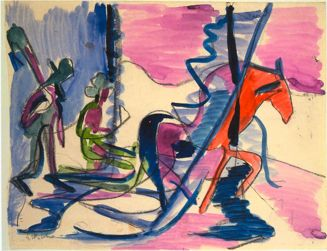

In [31]:
ex = bal.sample(1, random_state=cfg.seed + 2).iloc[0]
other = pd.Series(components.index).sample(1, random_state=cfg.seed + 3).iloc[0]
who = f"{show.lang_label(ex['language'])} annotator chose <b>{ex['emotion']}</b>"
show.show(
    show.figure(
        show.thumb(image_path(ex["painting"]), 180),
        f"<b>real:</b> {who}<br>for this painting",
        width=300,
    ),
    "<div style='font-size:2em;padding-top:70px'>→</div>",
    show.figure(
        show.thumb(image_path(other), 180),
        "<b>swapped:</b> same annotator and label, now paired with this painting's visual profile",
        width=300,
    ),
)

Score the interaction classifier with swapped visual profiles, and compare.

In [32]:
swap_null = analysis.concept_swap_null(
    bal,
    EMOS,
    components,
    cfg.analysis.n_permutations,
    cfg.analysis.cv_folds,
    cfg.analysis.logreg_C,
    cfg.seed,
)
real_int = inverted.loc["interaction", "balanced acc"]
emo_only = inverted.loc["emotion", "balanced acc"]
print(f"interaction, real paintings:     {real_int:.3f}")
print(
    f"interaction, swapped paintings:  mean {swap_null.mean():.3f}, max {swap_null.max():.3f}"
    "; real " + analysis.describe_p(real_int, swap_null, "swaps")
)
print(f"emotion alone:                   {emo_only:.3f}")
print(f"gain over swapped paintings:     {100 * (real_int - swap_null.mean()):+.1f} points")
print(f"gain over emotion alone:         {100 * (real_int - emo_only):+.1f} points")

interaction, real paintings:     0.464
interaction, swapped paintings:  mean 0.447, max 0.453; real beat all 200 swaps (p < 0.01)
emotion alone:                   0.457
gain over swapped paintings:     +1.7 points
gain over emotion alone:         +0.7 points


The real score against the swapped scores, with emotion alone for reference.

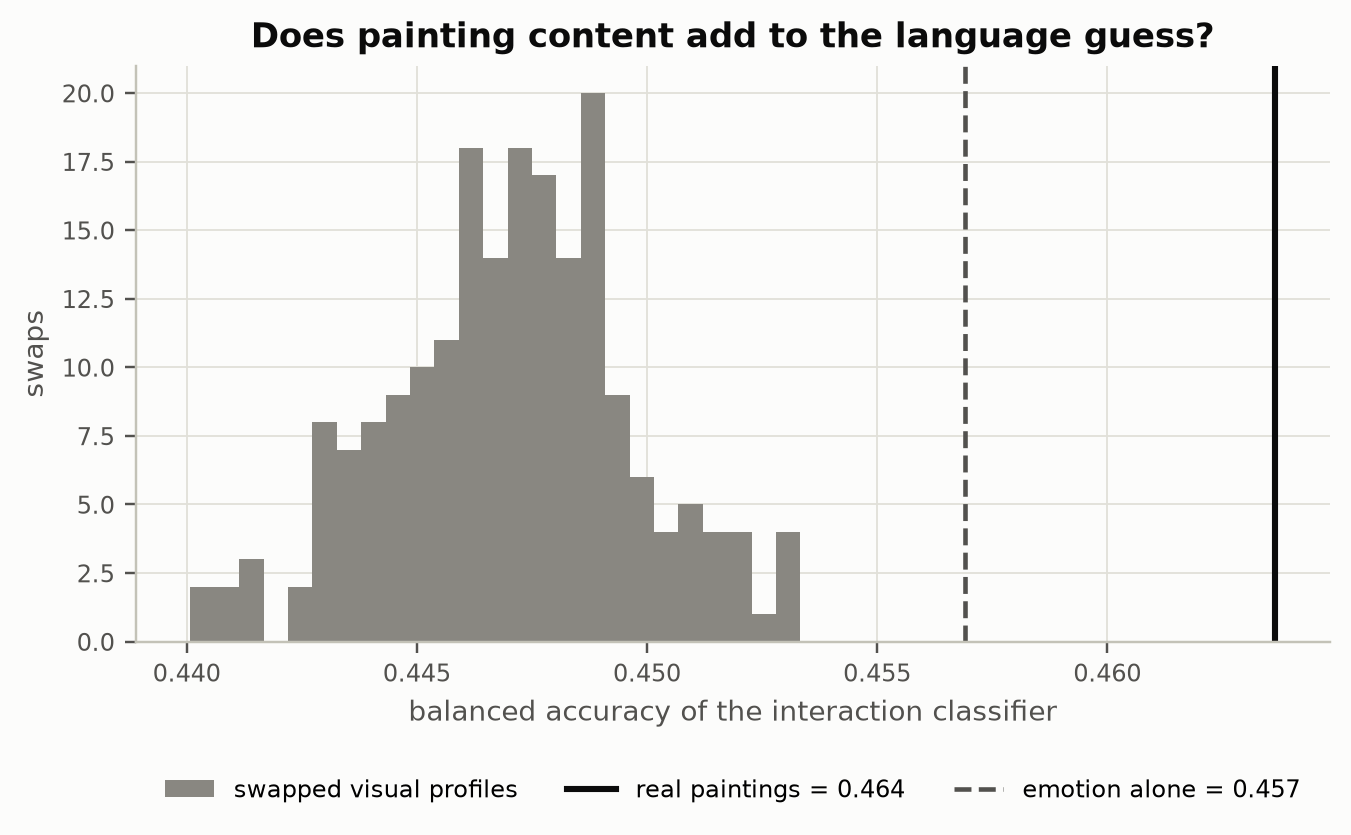

In [33]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(swap_null, bins=25, color=plots.NEUTRAL, label="swapped visual profiles")
ax.axvline(real_int, color=plots.INK, lw=2, label=f"real paintings = {real_int:.3f}")
ax.axvline(emo_only, color=plots.INK_2, lw=1.5, ls="--", label=f"emotion alone = {emo_only:.3f}")
ax.set_xlabel("balanced accuracy of the interaction classifier")
ax.set_ylabel("swaps")
ax.set_title("Does painting content add to the language guess?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plots.savefig(fig, "05b_concept_swap")
plt.show()

<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Supported, but small.</b> Real paintings beat every swapped version: 0.464 against a
swapped average of 0.447 (beat all 200 swaps, p < 0.01), a gain of +1.7 points.
Against the emotion alone (0.457) the gain is +0.7 points. The swapped versions
score below the emotion alone because their extra inputs carry no signal, and fitting
them costs the classifier a little accuracy. So what is in the painting carries some
language signal beyond label habits, but not much.

</div>

# Hinge · How much does the painting decide?

This section connects the two halves: it shows how small the language share is, sets
the ceiling for any model that predicts emotion from the painting, and checks the
bottleneck from section 1 against it.

## 6. How much of an emotion choice comes from the painting, and how much from the language?

<div style="border:1.5px solid #d4a27f;background:rgba(212,162,127,0.09);border-radius:6px;padding:10px 16px;margin:6px 0 10px;box-sizing:border-box;max-width:100%">
<div style="font-size:1.05em;line-height:1.5;font-style:italic">The critic is not the one who “lifts the rugs from under the feet of the naïve believers”</div>
<div style="opacity:0.75;margin-top:3px;font-size:0.92em">Latour, “Why Has Critique Run out of Steam?” (Critical Inquiry, 2004)</div>
</div>

**Hypothesis.** Language accounts for a real share of which emotion people pick. It
does so on its own, and in combination with the painting, when the same painting is
read differently in different languages.

**Method.**

- *Measure:* split the variation in emotion choice into four parts: the painting, the
  language, painting × language, and what is left over (a two-way analysis of
  variance, with each emotion coded as a yes/no choice).
- *If language didn't matter:* shuffle the language tags within each painting and
  recompute the language and painting × language shares, many times.
- *Reading it:* supported if both shares exceed their shuffled versions. Their size
  next to the painting share tells us how much language matters compared with the
  painting itself.

How the split works, on made-up labels for one emotion. Each person's yes/no choice is
the sum of an overall average, a painting part, a language part, a painting × language
part and what is left over. A part's share is how much it varies across all annotations.

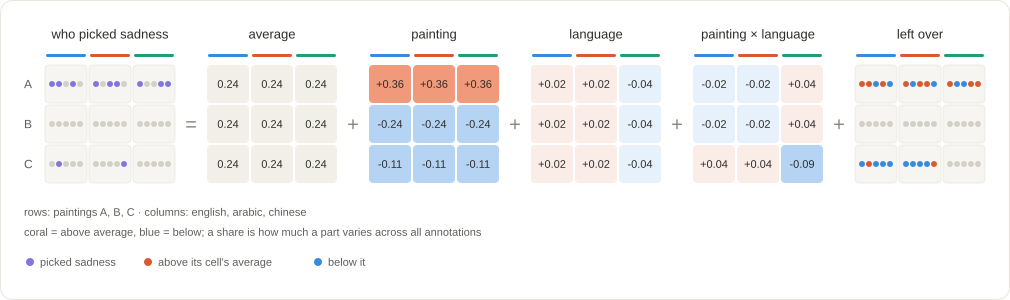

In [34]:
show.method_figure("07_variance_split")

The three parts on three paintings: one where the painting decides (almost everyone
picks the same emotion), one where the languages split the most, and a typical one.

● english,contentment ×5
● arabic,"contentment ×3, amusement ×2"
● chinese,contentment ×5
● english,"awe ×4, fear ×1"
● arabic,"excitement ×3, sadness ×1, something else ×1"
● chinese,"contentment ×4, fear ×1"
● english,"contentment ×2, fear ×1, something else ×1, excitement ×1"
● arabic,"excitement ×2, awe ×1, contentment ×1, something else ×1"
● chinese,contentment ×5

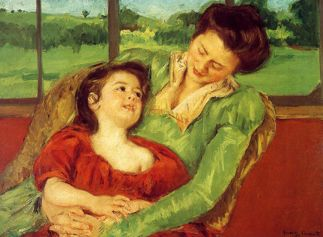
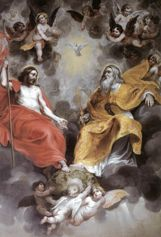
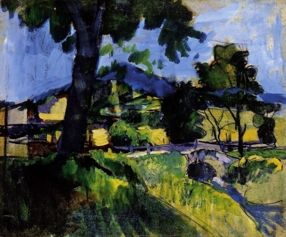

In [35]:
onehot = pd.get_dummies(bal["emotion"]).astype(float)
onehot[["painting", "language"]] = bal[["painting", "language"]]
cell = onehot.groupby(["painting", "language"]).mean()
by_painting = cell.groupby(level="painting").mean()
by_language = cell.groupby(level="language").mean()
interaction = (
    cell
    - by_painting.reindex(cell.index, level="painting").to_numpy()
    - by_language.reindex(cell.index, level="language").to_numpy()
    + cell.mean()
)
split = (interaction**2).sum(axis=1).groupby(level="painting").sum()

examples = {
    "the painting decides": top_share.nlargest(2).index[1],
    "the languages split": split.drop(gap_by_painting.idxmax()).idxmax(),
    "a typical painting": (split - split.median()).abs().idxmin(),
}
show.show(
    *[
        show.figure(
            show.thumb(image_path(p), 170),
            f"<i>{note}</i><br>{show.title(p)}" + show.emotion_counts(bal, p, LANGS),
            width=340,
        )
        for note, p in examples.items()
    ]
)

The four shares for each emotion and summed over all emotions, and the shuffled
baseline.

In [36]:
vs = analysis.variance_split(bal, EMOS)

rng = np.random.default_rng(cfg.seed)
null_rows = []
for _ in range(cfg.analysis.n_permutations):
    shuffled_lang = analysis.shuffle_labels_within(
        bal["language"].to_numpy(), bal["painting"].to_numpy(), rng
    )
    shuffled = bal.assign(language=shuffled_lang)
    null_rows.append(analysis.variance_split(shuffled, EMOS).loc["all emotions"])
vs_null = pd.DataFrame(null_rows)

real = vs.loc["all emotions"]
for term in ["language", "interaction"]:
    print(
        f"{term:12s} share {real[term]:.3f} | shuffled mean {vs_null[term].mean():.3f}, "
        f"max {vs_null[term].max():.3f} | "
        + analysis.describe_p(real[term], vs_null[term].to_numpy())
    )
vs

language     share 0.021 | shuffled mean 0.000, max 0.000 | beat all 200 shuffles (p < 0.01)
interaction  share 0.142 | shuffled mean 0.122, max 0.126 | beat all 200 shuffles (p < 0.01)


,painting,language,interaction,residual,noise_floor
amusement,0.097,2.639e-02,0.177,0.699,0.116
awe,0.103,1.673e-02,0.148,0.733,0.122
contentment,0.163,3.594e-02,0.142,0.659,0.110
excitement,0.098,5.294e-03,0.131,0.766,0.127
anger,0.077,3.276e-04,0.144,0.779,0.130
disgust,0.124,5.913e-03,0.140,0.731,0.122
fear,0.208,1.291e-02,0.129,0.651,0.108
sadness,0.240,7.571e-03,0.119,0.633,0.105
something else,0.092,2.483e-02,0.136,0.747,0.124
all emotions,0.144,2.120e-02,0.142,0.693,0.115


The shares for each emotion. The black tick shows how large the painting × language
part would be from noise alone.

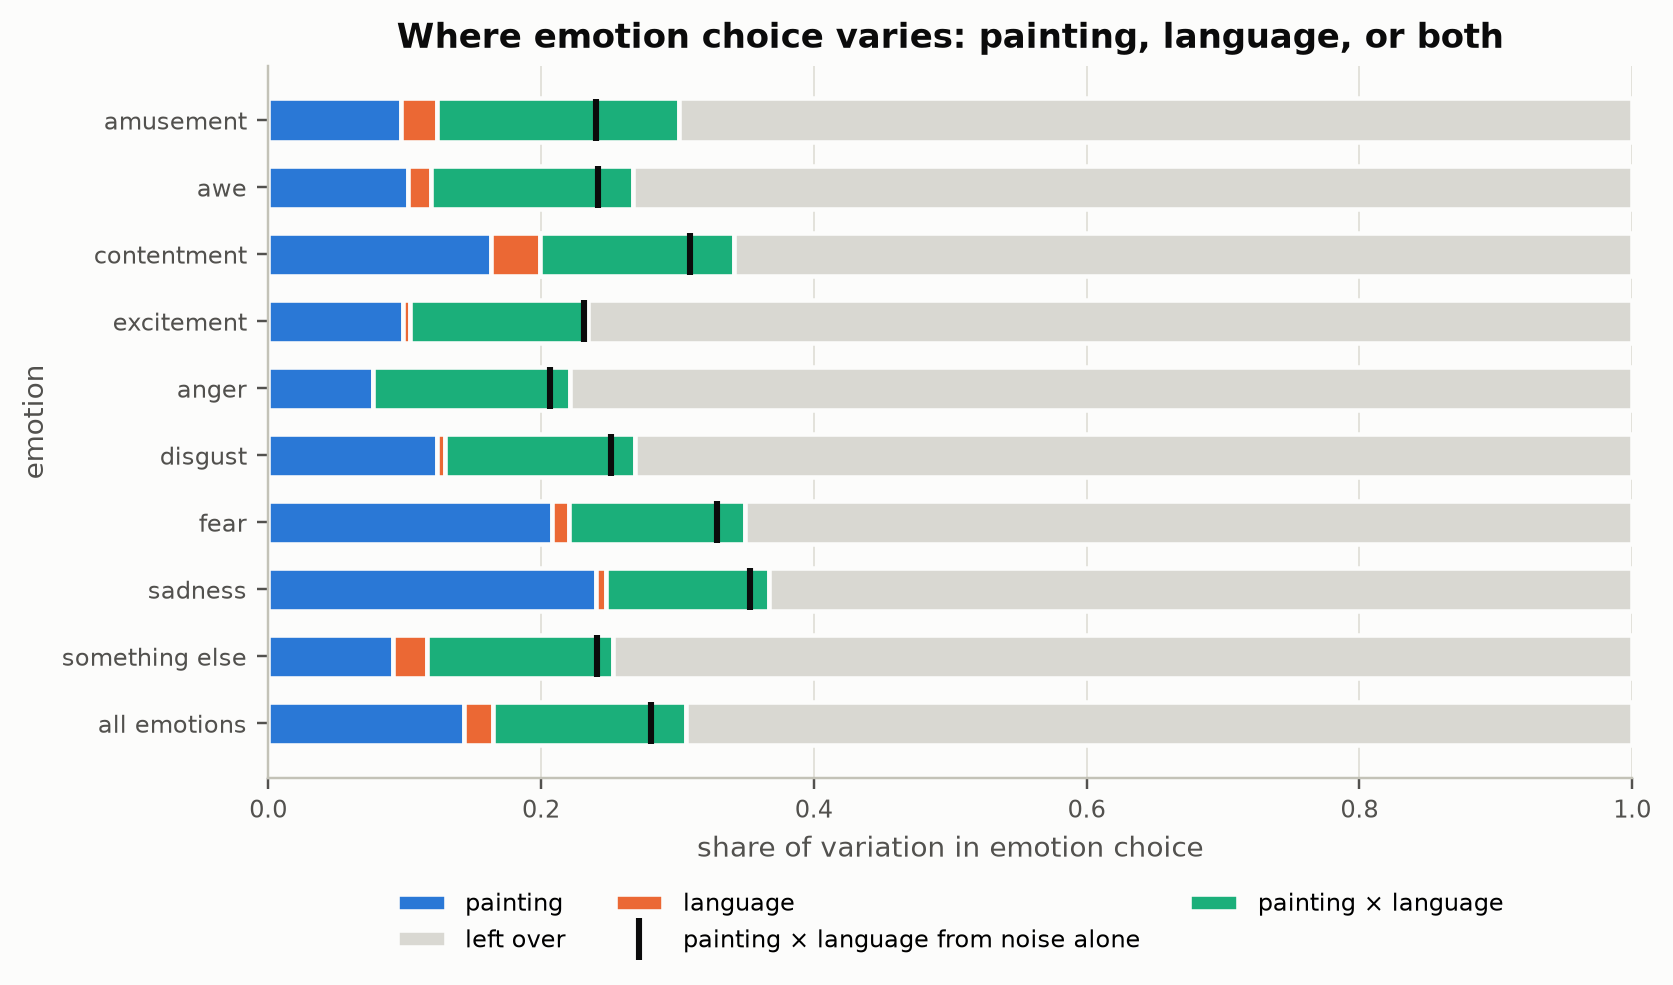

In [37]:
terms = ["painting", "language", "interaction", "residual"]
term_colors = {
    "painting": "#2a78d6",
    "language": "#eb6834",
    "interaction": "#1baf7a",
    "residual": "#d9d8d2",
}
term_labels = {
    "painting": "painting",
    "language": "language",
    "interaction": "painting × language",
    "residual": "left over",
}
fig, ax = plt.subplots(figsize=(8, 4.2))
left = np.zeros(len(vs))
for term in terms:
    ax.barh(
        vs.index,
        vs[term],
        left=left,
        color=term_colors[term],
        height=0.65,
        edgecolor="#fcfcfb",
        linewidth=1.5,
        label=term_labels[term],
    )
    left += vs[term].to_numpy()
floor_x = vs["painting"] + vs["language"] + vs["noise_floor"]
ax.plot(
    floor_x,
    range(len(vs)),
    "|",
    color=plots.INK,
    ms=14,
    mew=2,
    label="painting × language from noise alone",
)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of variation in emotion choice")
ax.set_ylabel("emotion")
ax.set_title("Where emotion choice varies: painting, language, or both")
handles, names = ax.get_legend_handles_labels()
order = [
    names.index(n)
    for n in [
        "painting",
        "left over",
        "language",
        "painting × language from noise alone",
        "painting × language",
    ]
]
ax.legend(
    [handles[i] for i in order],
    [names[i] for i in order],
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
)
plots.savefig(fig, "06b_variance_split")
plt.show()

How tied each emotion is to the painting. The painting share includes some chance
variation: with a handful of annotations per painting, painting averages differ even when
the painting does not matter. Moving each language's labels across paintings at random
shows how much (the grey part); the blue part is what the painting really explains.

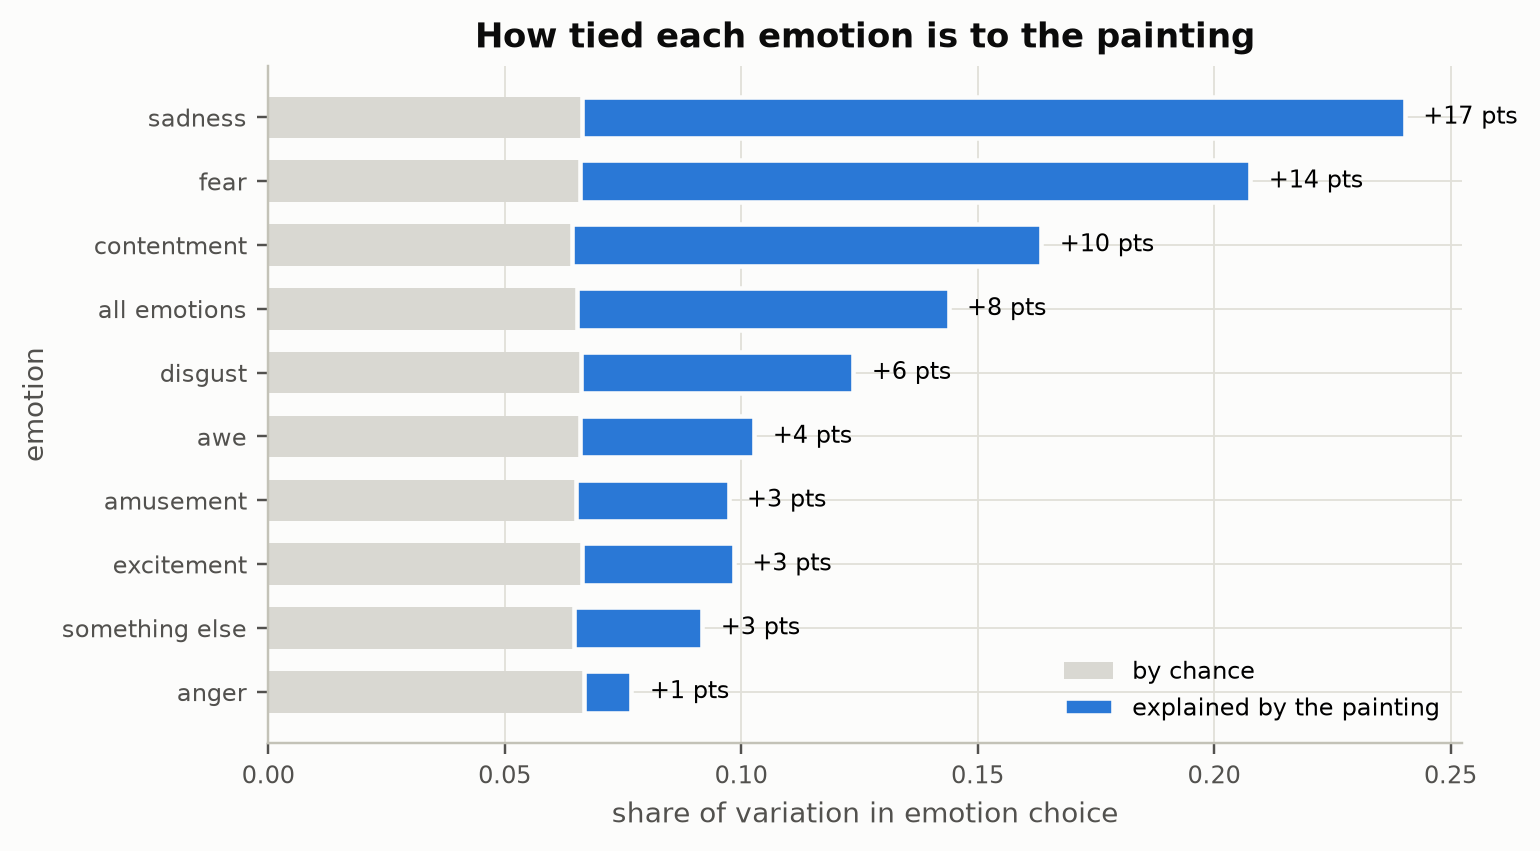

,painting share,by chance,above chance
sadness,0.240,0.066,0.174
fear,0.208,0.066,0.142
contentment,0.163,0.064,0.099
all emotions,0.144,0.065,0.079
disgust,0.124,0.066,0.058
awe,0.103,0.066,0.037
amusement,0.097,0.065,0.032
excitement,0.098,0.066,0.032
something else,0.092,0.065,0.027
anger,0.077,0.067,0.010


In [38]:
rng = np.random.default_rng(cfg.seed)
chance = pd.DataFrame(
    [
        analysis.variance_split(analysis.shuffle_emotions_within_language(bal, rng), EMOS)[
            "painting"
        ]
        for _ in range(cfg.analysis.n_permutations)
    ]
).mean()
painting_share = pd.DataFrame(
    {
        "painting share": vs["painting"],
        "by chance": chance,
        "above chance": vs["painting"] - chance,
    }
).sort_values("above chance")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(
    painting_share.index,
    painting_share["by chance"],
    color="#d9d8d2",
    height=0.65,
    label="by chance",
)
ax.barh(
    painting_share.index,
    painting_share["above chance"],
    left=painting_share["by chance"],
    color="#2a78d6",
    height=0.65,
    edgecolor="#fcfcfb",
    linewidth=1.5,
    label="explained by the painting",
)
for i, (_, r) in enumerate(painting_share.iterrows()):
    ax.annotate(
        f"+{100 * r['above chance']:.0f} pts",
        (r["painting share"], i),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
    )
ax.set_xlabel("share of variation in emotion choice")
ax.set_ylabel("emotion")
ax.set_title("How tied each emotion is to the painting")
ax.legend(loc="lower right")
plots.savefig(fig, "06c_painting_share_by_emotion")
plt.show()
painting_share.iloc[::-1]

<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Supported, but language is a small part.</b> Beyond chance, the painting explains
about 8 points of the variation in which emotion people pick; language on its own
explains about 2 points. Painting × language comes out at 14%, but shuffled languages
already give about 12%, so only about two points of it are real. Most of the variation
(about 69%) is left over: differences between individual annotators and noise, which we
cannot tell apart.

How tied an emotion is to the painting varies a lot: about 17 points above chance
for sadness and 14 for fear, but only about 1 point for anger.

</div>

### Back to the model

Section 1 showed the bottleneck works, modestly. Here we check where it works: its scores
per emotion next to how tied each emotion is to the painting.

In [39]:
forward["painting share above chance"] = painting_share["above chance"]
rho = spearmanr(forward.loc[EMOS, "bottleneck"], forward.loc[EMOS, "painting share above chance"])
print(f"rank correlation with painting share across emotions: {rho.statistic:.2f}")
forward

rank correlation with painting share across emotions: 0.87


,bottleneck,black box,other people,painting share above chance
amusement,0.040,0.046,0.007,0.032
awe,0.024,0.022,0.012,0.037
contentment,0.090,0.092,0.055,0.099
excitement,0.009,0.011,0.010,0.032
anger,0.004,0.005,-0.005,0.010
disgust,0.034,0.033,0.028,0.058
fear,0.074,0.072,0.088,0.142
sadness,0.057,0.070,0.112,0.174
something else,0.017,0.020,0.003,0.027
all emotions,0.051,0.054,0.042,0.079


Per emotion, ordered by how tied the emotion is to the painting.

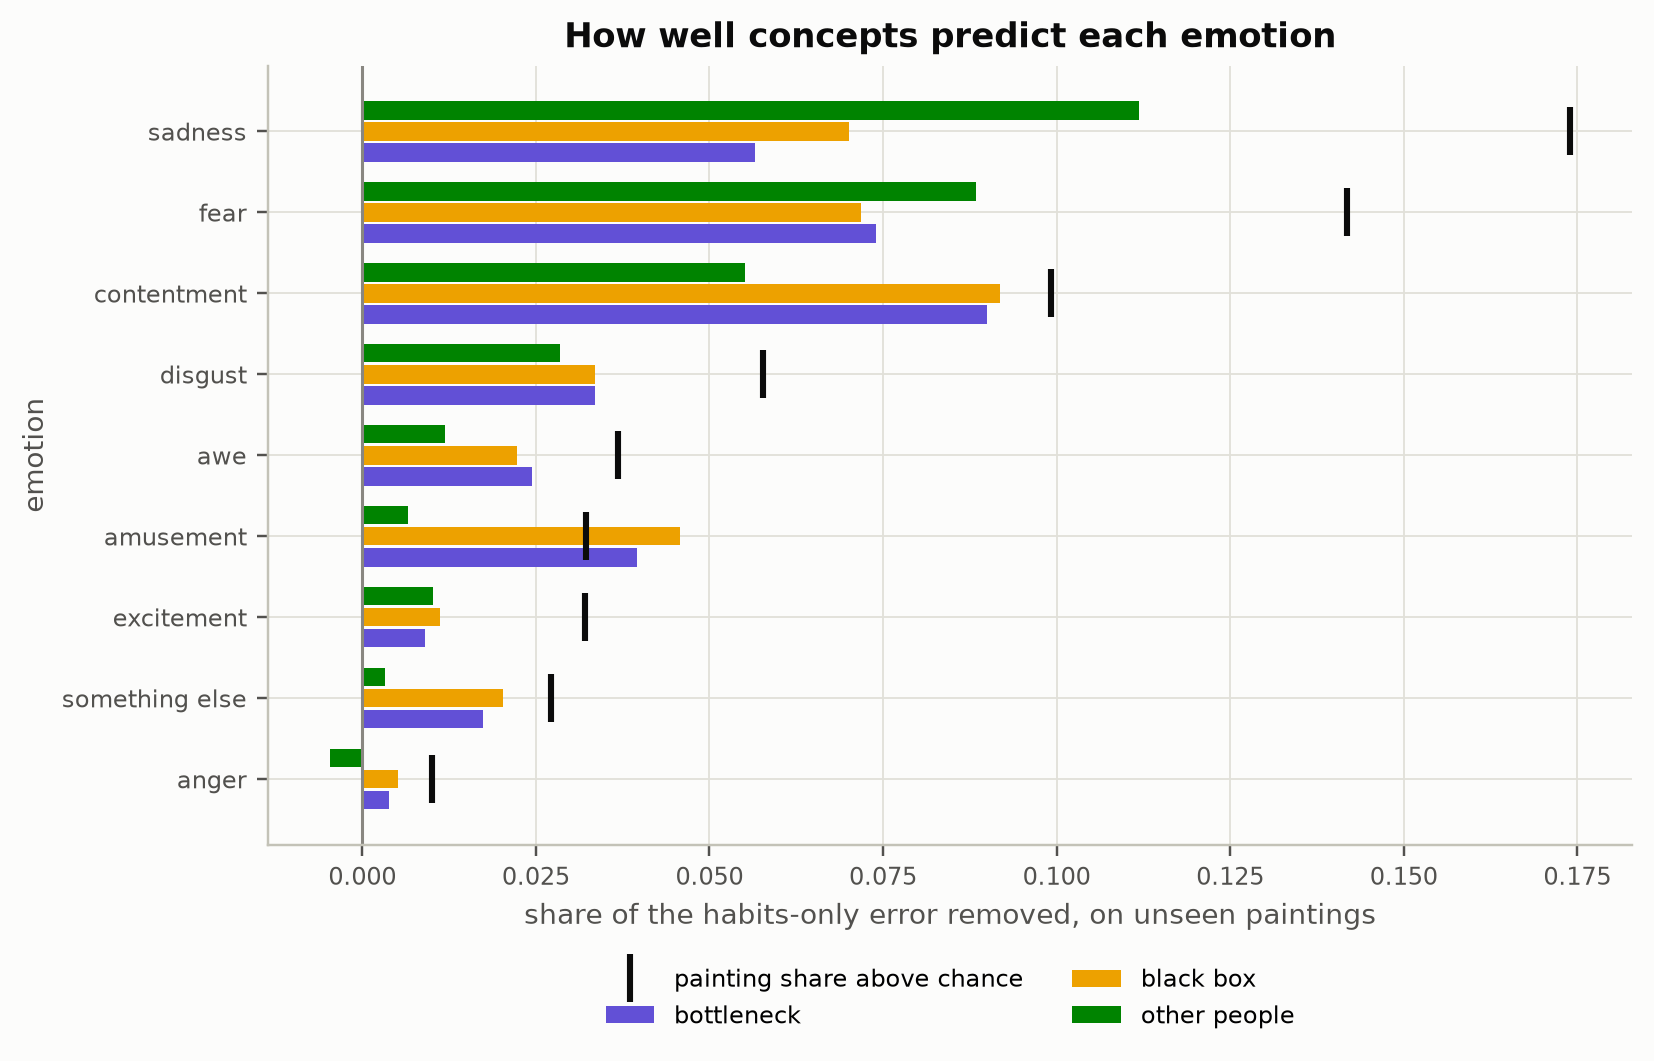

In [40]:
order = forward.loc[EMOS].sort_values("painting share above chance").index
fig, ax = plt.subplots(figsize=(8, 4.6))
y_pos, h = np.arange(len(order)), 0.26
for i, name in enumerate(["bottleneck", "black box", "other people"]):
    ax.barh(
        y_pos + (i - 1) * h,
        forward.loc[order, name],
        height=h - 0.03,
        color=plots.MODEL_COLORS[name],
        label=name,
    )
ax.plot(
    forward.loc[order, "painting share above chance"],
    y_pos,
    "|",
    color=plots.INK,
    ms=16,
    mew=2,
    label="painting share above chance",
)
ax.axvline(0, color=plots.NEUTRAL, lw=1)
ax.set_yticks(y_pos, order)
ax.set_xlabel("share of the habits-only error removed, on unseen paintings")
ax.set_ylabel("emotion")
ax.set_title("How well concepts predict each emotion")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
plots.savefig(fig, "06d_bottleneck_by_emotion")
plt.show()

<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

Its scores per emotion follow how tied each emotion is to the painting (rank correlation
0.87): contentment, fear and sadness at the top, anger barely predicted. The bottleneck
works as far as the painting decides. In absolute terms its 5% is small, and the room is
small too: beyond chance the painting explains about 8% of the variation in emotion choice,
measured on a different scale.

</div>

# Part II · Does the model behave as promised?

## 7. Do the results depend on the image encoder?

<div style="border:1.5px solid #d4a27f;background:rgba(212,162,127,0.09);border-radius:6px;padding:10px 16px;margin:6px 0 10px;box-sizing:border-box;max-width:100%">
<div style="font-size:1.05em;line-height:1.5">A hammer goes unnoticed while it works, and only shows itself when it breaks.</div>
<div style="opacity:0.75;margin-top:3px;font-size:0.92em">Heidegger, Being and Time (1927), paraphrased</div>
</div>

Everything so far used one CLIP model, trained mostly on English. A multilingual CLIP
sees the same images through a different model and can also read Arabic and Chinese,
which section 8 needs.

**Hypothesis.** Swapping in a multilingual CLIP leaves the main results unchanged.

**Method.**

- *Measure:* rerun three results with concept scores from the multilingual CLIP (same
  concept list, same English prompts): the bottleneck from section 1, the interaction
  classifier from section 4, and the swap test from section 5.
- *If the encoder didn't matter:* the numbers should be close to the originals, and the
  same tests should pass or fail.
- *Reading it:* supported if every conclusion stays the same.

How the test works: the same paintings, concepts and prompts go through two encoders,
and the same three tests run on each.

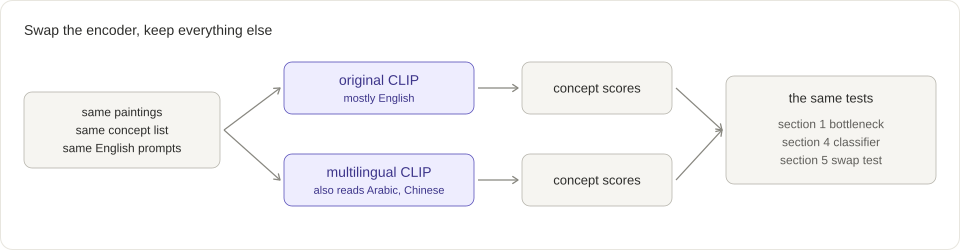

In [41]:
show.method_figure("08_encoder_swap")

Embed the images and concepts with the multilingual CLIP (only the first run does this).

In [42]:
memb = cfg.embedding
mclip = embed.load_clip(memb.multilingual_model, memb.multilingual_pretrained, DEVICE)
m_cache = (
    memb.cache_dir / f"images_{memb.multilingual_model}_{memb.multilingual_pretrained}.parquet"
)
m_img = embed.embed_images(
    painting_images, cfg.data.images_dir, m_cache, mclip, memb.batch_size, DEVICE
)


def mclip_scores(words, language):
    text = embed.embed_texts(
        [cfg.concepts.templates[language].format(w) for w in words], mclip, DEVICE
    )
    out = embed.concept_scores(m_img, text, words)
    out.index = out.index.map(image_to_painting)
    return out


m_scores = mclip_scores(concepts, "english")
print(f"{len(concepts)} concepts scored on {len(m_scores)} paintings")

152 concepts scored on 840 paintings


The three results with both encoders side by side.

In [43]:
m_components, _ = analysis.concept_components(m_scores, cfg.analysis.n_concept_components, cfg.seed)
X_m, _ = analysis.make_features(bal, "interaction", EMOS, m_components)
m_int = analysis.cv_balanced_accuracy(
    X_m, y, groups, cfg.analysis.cv_folds, cfg.analysis.logreg_C, cfg.seed
)
m_int_swaps = analysis.concept_swap_null(
    bal,
    EMOS,
    m_components,
    cfg.analysis.n_permutations,
    cfg.analysis.cv_folds,
    cfg.analysis.logreg_C,
    cfg.seed,
)
m_probs, _ = cbm.forward_cv(bal, m_scores, EMOS, LANGS, cfg.analysis.cv_folds, Cs, cfg.seed)
m_fwd = cbm.explained(bal, m_probs, habits, EMOS)["all emotions"]
m_fwd_swaps = cbm.forward_swap_null(
    bal,
    m_scores,
    EMOS,
    LANGS,
    cfg.analysis.n_permutations,
    cfg.analysis.cv_folds,
    fixed_C,
    cfg.seed,
)

encoders = pd.DataFrame(
    {
        "original CLIP": [
            real_int,
            swap_null.mean(),
            analysis.describe_p(real_int, swap_null, "swaps"),
            fwd_real,
            fwd_swaps.max(),
            analysis.describe_p(fwd_real, fwd_swaps, "swaps"),
        ],
        "multilingual CLIP": [
            m_int,
            m_int_swaps.mean(),
            analysis.describe_p(m_int, m_int_swaps, "swaps"),
            m_fwd,
            m_fwd_swaps.max(),
            analysis.describe_p(m_fwd, m_fwd_swaps, "swaps"),
        ],
    },
    index=[
        "section 4: interaction score",
        "section 5: swapped mean",
        "section 5: real vs swaps",
        "section 1: bottleneck score",
        "section 1: swapped max",
        "section 1: real vs swaps",
    ],
)
encoders

,original CLIP,multilingual CLIP
section 4: interaction score,0.464,0.468
section 5: swapped mean,0.447,0.447
section 5: real vs swaps,beat all 200 swaps (p < 0.01),beat all 200 swaps (p < 0.01)
section 1: bottleneck score,0.051,0.049
section 1: swapped max,-0.009,-0.012
section 1: real vs swaps,beat all 200 swaps (p < 0.01),beat all 200 swaps (p < 0.01)


<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Supported.</b> With the multilingual CLIP every conclusion stays the same. The
interaction classifier scores 0.468 (0.464 before) and still beats all 200 swaps; the
bottleneck removes 4.9% of the habits-only error (5.1% before) and still beats all 200
swaps. These results do not hinge on the choice of encoder.

</div>

## 8. Do concepts in the annotators' own languages work better?

<div style="border:1.5px solid #d4a27f;background:rgba(212,162,127,0.09);border-radius:6px;padding:10px 16px;margin:6px 0 10px;box-sizing:border-box;max-width:100%">
<div style="font-size:1.05em;line-height:1.5;font-style:italic">“one must recognize that there is a supplement at the source”</div>
<div style="opacity:0.75;margin-top:3px;font-size:0.92em">Derrida, Of Grammatology (1967; trans. Spivak), Part II, “…That Dangerous Supplement…”</div>
</div>

A natural extension adds concepts in each language: translations of the generic list, and
"native" concepts drawn from what annotators actually wrote. The idea is that each
language's annotators see paintings through their own vocabulary. But people write about
how a painting makes them feel as well as what is in it, so native lists also contain
feeling words ("sad", "peaceful", 满足 "content"). Those sit close to the emotion labels
themselves.

**Hypothesis.** Each language's emotion choices are predicted better with concepts in
that language than with the generic English list, and native words help because of what
they say about the painting, not because of feeling words.

**Method.**

- *Measure:* the section 1 bottleneck with three vocabularies of the same length, all scored
  with the multilingual CLIP:
  - **generic:** the English list used so far
  - **translated:** the same list in Arabic and Chinese; each language's output uses its
    own translation
  - **native:** the words that appear in the most explanations in each language, taken
    from the original ArtELingo release and only from paintings outside our set (over
    70,000), so they cannot leak anything about the paintings we test on. Words that are
    not concepts at all (function words, fillers, fragments such as "don't" or 不由) are
    left out, and words with the same meaning count once (女人 and 女子 both mean
    "woman"; "man", "men" and "man's" are one word).
  - **native, no feeling words:** the same lists with feeling words dropped as well, and
    the next most common words moved up. A feeling word names an emotion, a mood or a
    judgement ("sad", "peaceful", "beautiful", "boring"); words for things one could point
    to in the painting stay, including visible qualities such as "dark" or "smile"<sup>1</sup>
- *If the vocabulary didn't matter:* the differences from the generic list stay within
  what resampling the paintings produces.
- *Reading it:* the first part is supported if a language's own vocabulary beats the
  generic list for that language. The second is supported if the native lists keep their
  gain without feeling words; if the gain disappears, it came from words that restate the
  emotion.

How the test works: which concept list each language's head uses under each vocabulary,
and why the native lists cannot leak anything about the paintings we test on.

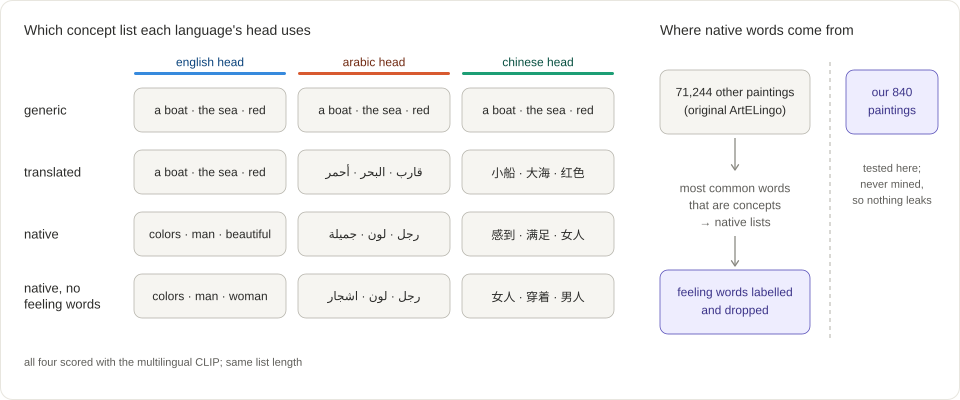

In [44]:
show.method_figure("09_vocabularies")

Load the native lists (mined by `scripts/mine_native_vocab.py`) and the word labels, and
show the most common words in each language: feeling words in violet, words that are not
concepts struck through, and repeats of a word already listed in grey.

In [45]:
labels = pd.read_csv(
    REPO_ROOT / "concepts" / "native_v1_labels.tsv", sep="\t", keep_default_na=False
)
ranked = {
    lang: pd.read_csv(
        REPO_ROOT / "concepts" / f"native_v1_{lang}.tsv", sep="\t", keep_default_na=False
    ).merge(labels[labels["language"] == lang], on="word", how="left", validate="1:1")
    for lang in LANGS
}
distinct = {lang: t[t["same_as"] == ""] for lang, t in ranked.items()}
native = {
    lang: t.loc[t["label"] != "none", "word"].head(len(concepts)).tolist()
    for lang, t in distinct.items()
}
no_feeling = {
    lang: t.loc[t["label"] == "concept", "word"].head(len(concepts)).tolist()
    for lang, t in distinct.items()
}
feeling_share = pd.Series(
    {
        lang: ranked[lang].set_index("word").loc[native[lang], "label"].eq("feeling").mean()
        for lang in LANGS
    },
    name="feeling words in the native list",
)

STYLE = {
    "feeling": f"color:{plots.VOCAB_COLORS['native']};font-weight:600",
    "none": "text-decoration:line-through;opacity:0.55",
    "concept": "",
}


def word_line(row):
    gloss = f" <i style='opacity:0.7'>(trans.) {row.translation}</i>" if row.translation else ""
    if row.same_as:
        return f"<span style='opacity:0.45'>{row.word} = {row.same_as}</span>{gloss}"
    return f"<span style='{STYLE[row.label]}'>{row.word}</span>{gloss}"


show.show(
    *[
        f"<div>{show.lang_label(lang)}<br>"
        + "<br>".join(word_line(r) for r in ranked[lang].head(20).itertuples())
        + "</div>"
        for lang in LANGS
    ]
)
feeling_share.map("{:.0%}".format)

english    24%
arabic     14%
chinese    30%
Name: feeling words in the native list, dtype: str

How well do the model's word labels agree with mine? I labelled the English and Chinese
words without seeing the model's labels. The test above depends only
on feeling word or not, so agreement is shown for that split as well as for all three
labels.

In [46]:
from sklearn.metrics import cohen_kappa_score

for lang in ["english", "chinese"]:
    path = REPO_ROOT / "concepts" / f"native_v1_{lang}_check.tsv"
    if not path.exists():
        print(f"{lang}: no labels of mine yet")
        continue
    check = pd.read_csv(path, sep="\t", keep_default_na=False, dtype={"label": str})
    both = check[check["label"] != ""].merge(
        ranked[lang], on="word", suffixes=(" (mine)", " (model)")
    )
    mine, model = both["label (mine)"], both["label (model)"]
    feel_r, feel_m = mine == "feeling", model == "feeling"
    print(f"{lang}: {len(both)} of {len(check)} words labelled")
    print(
        f"  three labels:          agree on {(mine == model).mean():.0%}, "
        f"Cohen's kappa {cohen_kappa_score(mine, model):.2f}"
    )
    print(
        f"  feeling word or not:   agree on {(feel_r == feel_m).mean():.0%}, "
        f"Cohen's kappa {cohen_kappa_score(feel_r, feel_m):.2f}"
    )
    for (r, m), words in both[mine != model].groupby([mine, model])["word"]:
        print(f"  mine {r}, model {m}: " + ", ".join(words))

english: 300 of 300 words labelled
  three labels:          agree on 93%, Cohen's kappa 0.85
  feeling word or not:   agree on 97%, Cohen's kappa 0.92
  mine concept, model none: hard, he's, making, she's, real, doing, seeing, showing, taking, thought, come, viewer, bring, attention
  mine feeling, model concept: warm, strong, bold
  mine feeling, model none: sense, want, used, different, important
chinese: 300 of 300 words labelled
  three labels:          agree on 92%, Cohen's kappa 0.84
  feeling word or not:   agree on 98%, Cohen's kappa 0.96
  mine concept, model feeling: 温暖, 精致, 氛围, 人心
  mine concept, model none: 两个, 样子, 许多, 几个, 充满, 东西, 一脸, 露出, 生长, 整体, 不同, 微微, 组成, 那里, 一对, 摆放, 形成, 满脸, 一块
  mine none, model concept: 留着
  mine none, model feeling: 之感


Fit the bottleneck with each vocabulary and compare per language.

In [47]:
translated = {"english": m_scores} | {
    lang: mclip_scores(path.read_text().splitlines(), lang)
    for lang, path in cfg.concepts.translated.items()
}
native_scores = {lang: mclip_scores(native[lang], lang) for lang in LANGS}
no_feeling_scores = {lang: mclip_scores(no_feeling[lang], lang) for lang in LANGS}
vocab_probs = {
    "generic": m_probs,
    "translated": cbm.forward_cv(bal, translated, EMOS, LANGS, cfg.analysis.cv_folds, Cs, cfg.seed)[
        0
    ],
    "native": cbm.forward_cv(bal, native_scores, EMOS, LANGS, cfg.analysis.cv_folds, Cs, cfg.seed)[
        0
    ],
    "native, no feeling words": cbm.forward_cv(
        bal, no_feeling_scores, EMOS, LANGS, cfg.analysis.cv_folds, Cs, cfg.seed
    )[0],
}
rows_of = {lang: (bal["language"] == lang).to_numpy() for lang in LANGS}
vocabularies = pd.DataFrame(
    {
        name: [
            cbm.explained(bal, pr, habits, EMOS, rows=rows_of[lang])["all emotions"]
            for lang in LANGS
        ]
        for name, pr in vocab_probs.items()
    },
    index=LANGS,
)

for name in ["translated", "native", "native, no feeling words"]:
    for lang in LANGS:
        if name == "translated" and lang == "english":
            continue  # identical to generic
        diff = cbm.bootstrap_difference(
            bal,
            vocab_probs[name],
            vocab_probs["generic"],
            habits,
            EMOS,
            cfg.analysis.n_bootstrap,
            cfg.seed,
            rows=rows_of[lang],
        )
        lo, hi = np.quantile(diff, [0.025, 0.975])
        vocabularies.loc[lang, f"{name} - generic (95% range)"] = (
            f"{100 * (vocabularies.loc[lang, name] - vocabularies.loc[lang, 'generic']):+.1f} pts "
            f"({100 * lo:+.1f} to {100 * hi:+.1f})"
        )
vocabularies.iloc[:, 4:]

,translated - generic (95% range),native - generic (95% range),"native, no feeling words - generic (95% range)"
english,NaN,+0.8 pts (+0.5 to +1.1),+0.5 pts (+0.3 to +0.8)
arabic,+0.2 pts (-0.0 to +0.4),+0.4 pts (+0.1 to +0.6),+0.2 pts (-0.0 to +0.4)
chinese,-0.1 pts (-0.4 to +0.3),+0.4 pts (-0.1 to +1.0),+0.2 pts (-0.2 to +0.7)


The four vocabularies per language.

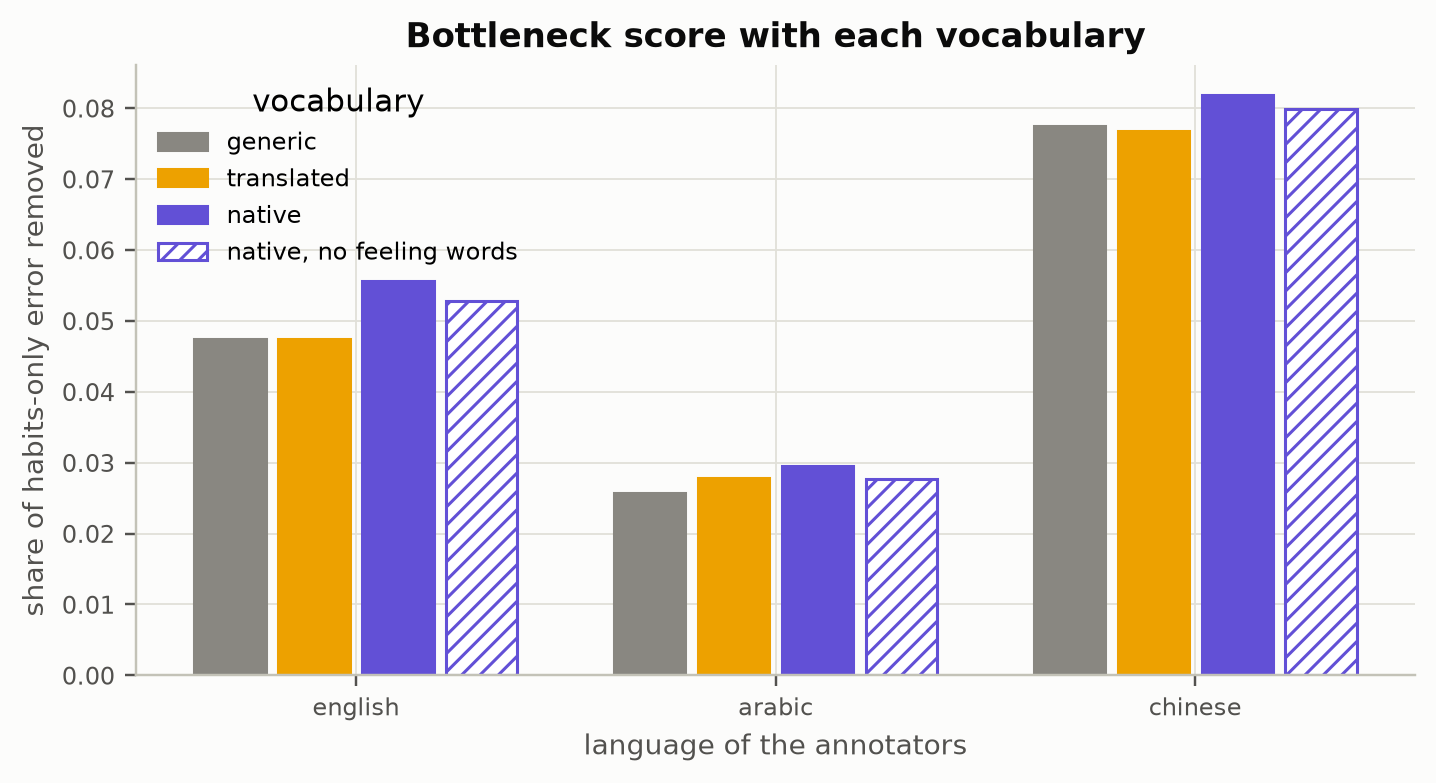

In [48]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x_pos, w = np.arange(len(LANGS)), 0.2
for i, name in enumerate(plots.VOCAB_COLORS):
    hatched = name == "native, no feeling words"  # the native list, filtered: same colour
    ax.bar(
        x_pos + (i - 1.5) * w,
        vocabularies[name],
        width=w - 0.03,
        label=name,
        color="white" if hatched else plots.VOCAB_COLORS[name],
        edgecolor=plots.VOCAB_COLORS[name],
        hatch="////" if hatched else None,
    )
ax.set_xticks(x_pos, LANGS)
ax.set_xlabel("language of the annotators")
ax.set_ylabel("share of habits-only error removed")
ax.set_title("Bottleneck score with each vocabulary")
ax.legend(title="vocabulary", loc="upper left")
plots.savefig(fig, "08b_vocabularies")
plt.show()

<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Partly supported, and partly feeling words.</b> Native vocabularies beat the generic
list by 0.8 points for English and 0.4 for Arabic, more than resampling the paintings
produces; for Chinese the +0.4 stays within that range. Mining them from over 70,000
paintings instead of a few hundred barely changes this. Translations do not help: for
Arabic and Chinese they land within a fraction of a point of the generic list. So what
helps is not the language of the concepts but what they are about.
<br><br>
Without feeling words, the gain shrinks in every language, to +0.5 for English and +0.2
for Arabic and Chinese, and only the English gain stays clearly above what resampling
produces. Feeling words make up 14 to 30% of the native lists but carry a third to half of
their gain. Part of what native words add is the emotion label coming back in as a
concept.

</div>

<small><sup>1</sup> For interest: I labelled the 300 most common English and Chinese words
without seeing the model's labels, in one pass. On feeling word or not, they agree
with the model on 97% of English words (Cohen's kappa 0.92) and 98% of Chinese words
(0.96); across all three labels, on 93% (0.85) and 92% (0.84).</small>

## 9. Do edits to the concepts help the way they should?

<div style="border:1.5px solid #d4a27f;background:rgba(212,162,127,0.09);border-radius:6px;padding:10px 16px;margin:6px 0 10px;box-sizing:border-box;max-width:100%">
<div style="font-size:1.05em;line-height:1.5;font-style:italic">“‘the doer’ is merely a fiction added to the deed”</div>
<div style="opacity:0.75;margin-top:3px;font-size:0.92em">Nietzsche, On the Genealogy of Morals (1887), I §13</div>
<div style="margin-top:10px;font-size:1.05em;line-height:1.5;font-style:italic">“there may be little or no direct introspective access to higher order cognitive processes”</div>
<div style="opacity:0.75;margin-top:3px;font-size:0.92em">Nisbett &amp; Wilson, “Telling More Than We Can Know” (Psychological Review, 1977)</div>
</div>

A concept bottleneck promises that a person can correct its concepts and get better
predictions. We test that promise against edits that should not help.

**Hypothesis.** Raising the concepts that annotators mention in their explanations
improves the bottleneck's predictions more than raising the same number of random
concepts.

**Method.**

- *Measure:* for each painting, find the concepts that its English annotators mention
  ("boat", "sea", "red"; only one-word concepts can be matched in text). Raise those
  concepts' scores to a high level, and see how the section 1 bottleneck's score changes
  for the Arabic and Chinese annotators of the same painting, whose explanations we do not
  use. The score is the share of the habits-only error that the bottleneck removes; higher
  is better.
- *If edits were arbitrary:* raise the same number of random, unmentioned concepts
  instead, many times (sham edits).
- *Reading it:* supported if real edits beat every sham edit. A useful bottleneck should
  also do better than with no edit at all.

How the test works, on a made-up painting: a real edit raises the concepts its English
explanation mentions; a sham edit raises the same number of random concepts.

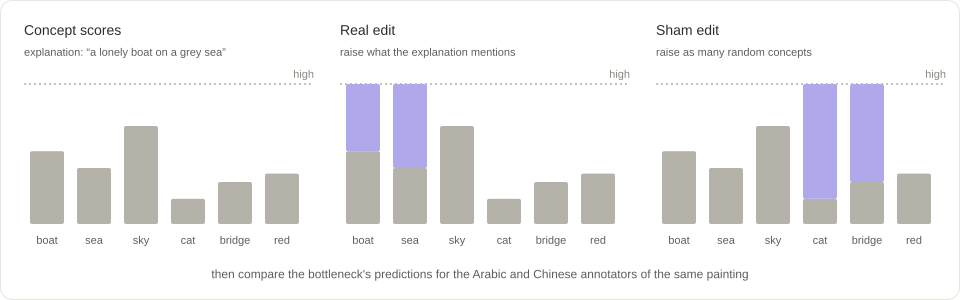

In [49]:
show.method_figure("10_edit_test")

The edit on one painting: the concepts its English annotators mention, and one random
sham set of the same size.


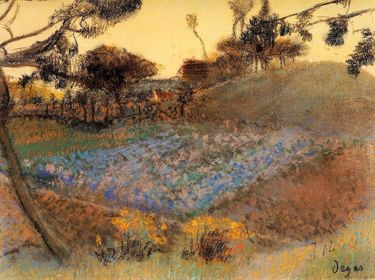

93 one-word concepts; 2.7 mentioned per painting on average


In [50]:
english_text = ann[(ann["language"] == "english") & ann["painting"].isin(painting_images.index)]
mentioned = cbm.mentions(english_text, concepts).reindex(scores.index, fill_value=False)
rng = np.random.default_rng(cfg.seed)
sham_example = cbm.sham_choice(mentioned, rng)
ex = mentioned.sum(axis=1)[lambda s: s >= 3].sample(1, random_state=cfg.seed).index[0]
show.show(
    show.figure(show.thumb(image_path(ex), 200), show.title(ex), width=320),
    f"<div style='max-width:420px'><b>mentioned (real edit):</b> "
    f"{', '.join(mentioned.columns[mentioned.loc[ex]])}<br><br>"
    f"<b>random (sham edit):</b> {', '.join(sham_example.columns[sham_example.loc[ex]])}</div>",
)
print(
    f"{mentioned.shape[1]} one-word concepts; {mentioned.sum(axis=1).mean():.1f} mentioned per "
    "painting on average"
)

Score the bottleneck with no edit, with real edits and with many sham edits.

In [51]:
level = scores.quantile(0.9)  # "high": the 90th percentile of each concept
eval_langs = ["arabic", "chinese"]
eval_rows = bal["language"].isin(eval_langs).to_numpy()


def edited_score(edit):
    probs = cbm.repredict(bal, fwd_fits, cbm.raise_concepts(scores, edit, level), EMOS, eval_langs)
    return cbm.explained(bal, probs, habits, EMOS, rows=eval_rows)["all emotions"]


no_edit = cbm.explained(
    bal, cbm.repredict(bal, fwd_fits, scores, EMOS, eval_langs), habits, EMOS, rows=eval_rows
)["all emotions"]
real_edit = edited_score(mentioned)
sham_edits = np.array(
    [edited_score(cbm.sham_choice(mentioned, rng)) for _ in range(cfg.analysis.n_permutations)]
)
print(f"no edit:      {no_edit:.4f}")
print(f"real edits:   {real_edit:.4f} ({100 * (real_edit - no_edit):+.2f} pts)")
print(
    f"sham edits:   mean {sham_edits.mean():.4f}, max {sham_edits.max():.4f}; real "
    + analysis.describe_p(real_edit, sham_edits, "sham edits")
)

no edit:      0.0510
real edits:   0.0501 (-0.09 pts)
sham edits:   mean 0.0483, max 0.0507; real p = 0.020


Real edits against sham edits, with no edit for reference.

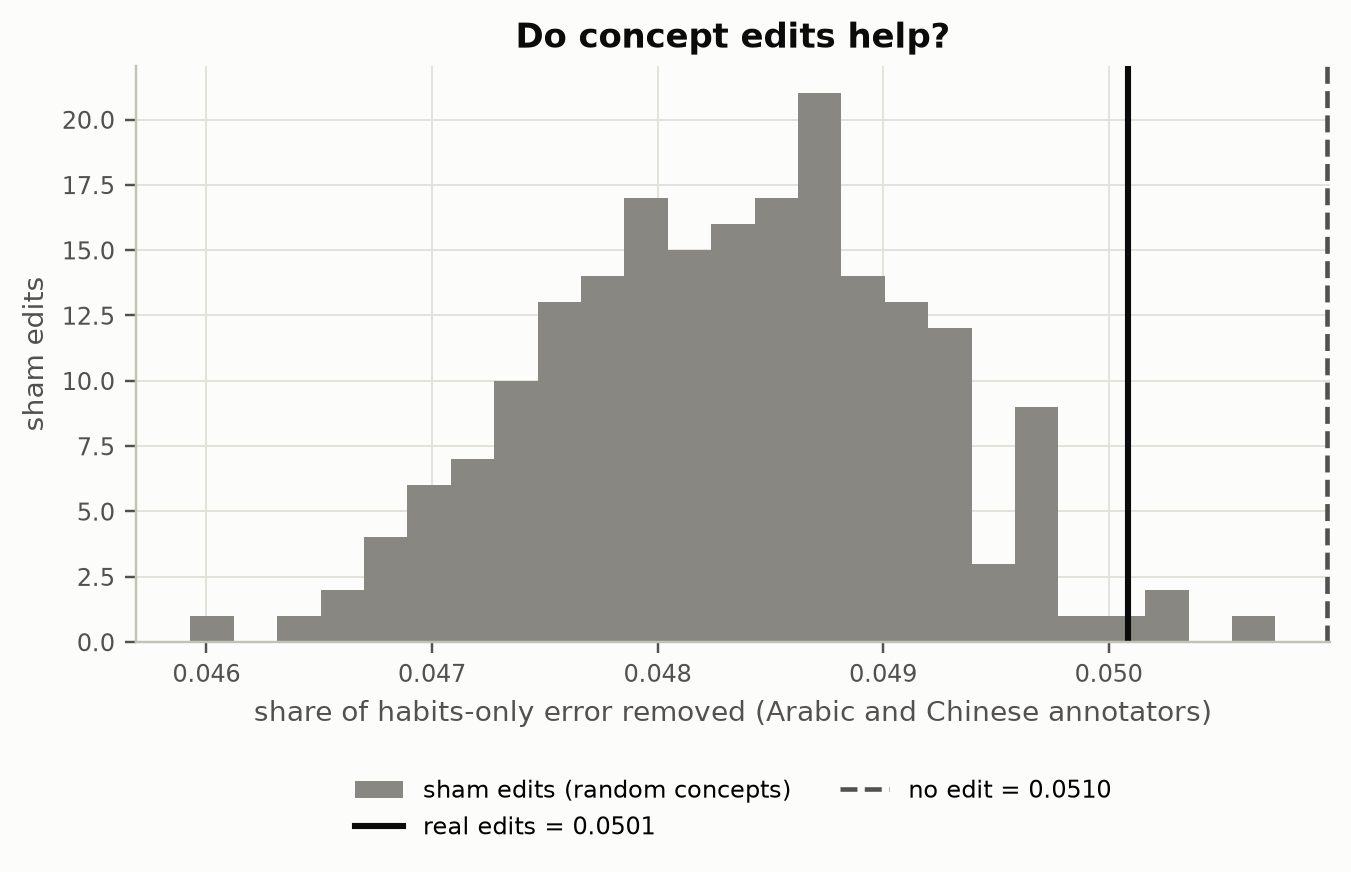

In [52]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(sham_edits, bins=25, color=plots.NEUTRAL, label="sham edits (random concepts)")
ax.axvline(real_edit, color=plots.INK, lw=2, label=f"real edits = {real_edit:.4f}")
ax.axvline(no_edit, color=plots.INK_2, lw=1.5, ls="--", label=f"no edit = {no_edit:.4f}")
ax.set_xlabel("share of habits-only error removed (Arabic and Chinese annotators)")
ax.set_ylabel("sham edits")
ax.set_title("Do concept edits help?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plots.savefig(fig, "09b_edits")
plt.show()

<div style="border:2px solid #6250d6;background:rgba(98,80,214,0.07);border-radius:6px;padding:10px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Not supported.</b> Raising the concepts that annotators mention does not improve
the predictions: the score drops slightly, from 0.0510 to 0.0501. Real edits do better
than random ones on average (random edits hurt more, 0.0483), but a few random edits match
them (p = 0.020). Correcting the concepts toward what people say they saw does not make
the bottleneck better at predicting what they chose.

</div>

## What we found

The same questions, with what we found.

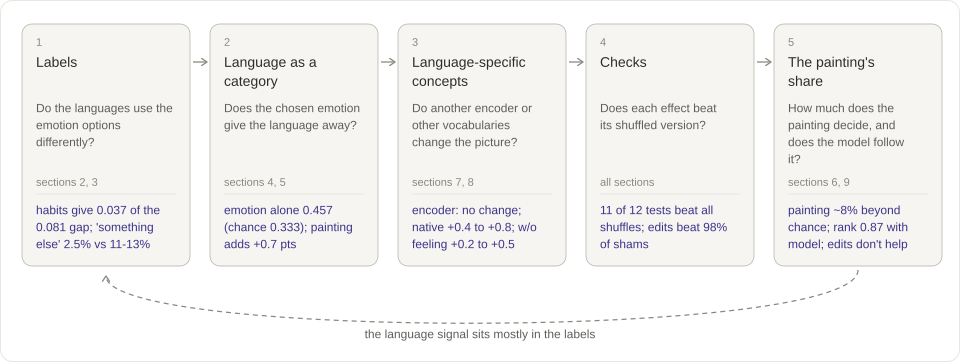

In [53]:
tests = (
    [(gap_real, gap_shuffled), (gap_real, gap_habits)]
    + [(inverted.loc[k, "balanced acc"], cbm_nulls[k]) for k in cbm_nulls]
    + [(vs.loc["all emotions", t], vs_null[t].to_numpy()) for t in ["language", "interaction"]]
    + [(real_int, swap_null), (fwd_real, fwd_swaps), (m_int, m_int_swaps), (m_fwd, m_fwd_swaps)]
    + [(real_edit, sham_edits)]
)
n_beat = sum(int((null >= r).sum() == 0) for r, null in tests)
native_gain = 100 * (vocabularies["native"] - vocabularies["generic"])
plain_gain = 100 * (vocabularies["native, no feeling words"] - vocabularies["generic"])
other_pct = 100 * other_share["share"]
above = 100 * painting_share["above chance"]
edits = "edits don't help" if real_edit <= no_edit else "edits help"
chain_results = {
    1: f"habits give {gap_habits.mean():.3f} of the {gap_real:.3f} gap; 'something else' "
    f"{other_pct['chinese']:.1f}% vs {other_pct.drop('chinese').min():.0f}-"
    f"{other_pct.drop('chinese').max():.0f}%",
    2: f"emotion alone {emo_only:.3f} (chance 0.333); painting adds "
    f"{100 * (real_int - emo_only):+.1f} pts",
    3: f"encoder: no change; native {native_gain.min():+.1f} to {native_gain.max():+.1f}; "
    f"w/o feeling {plain_gain.min():+.1f} to {plain_gain.max():+.1f}",
    4: f"{n_beat} of {len(tests)} tests beat all shuffles; edits beat "
    f"{(sham_edits < real_edit).mean():.0%} of shams",
    5: f"painting ~{above['all emotions']:.0f}% beyond chance; rank {rho.statistic:.2f} "
    f"with model; {edits}",
}
show.chain_results(chain_results)

- **A concept bottleneck predicts emotion choices, within the ceiling (sections 1
  and 6: supported).** It removes about 5% of the habits-only error on unseen paintings, follows
  how tied each emotion is to the painting, and costs little against a black box.
- **How tied an emotion is to the painting sets a ceiling (section 6).** The painting
  explains about 17 points beyond chance for sadness and 14 for fear, but only
  about 1 for anger. This is roughly the ceiling for any model that predicts
  emotion from the painting alone, a concept bottleneck included.
- **People disagree more across languages than within one, and about half of that is
  about specific paintings (section 2: supported).** The gap is far outside what shuffled
  languages produce. Each language's label habits alone produce about half of it; the
  rest is tied to particular paintings.
- **Languages use "something else" very differently (section 3: supported).** Chinese
  annotators pick it for about 2.5% of annotations, English and Arabic for 11 to 13%.
- **Each language has its own label habits (sections 2 and 4: supported).** On the same
  paintings, Chinese annotators pick contentment about half the time and rarely use
  "something else"; Arabic annotators pick amusement and awe more often. The emotion
  alone is enough to guess the language well above chance (0.46 against 0.33).
- **What is in the painting adds only a little (section 5: supported, but small).**
  Combining the emotion with the painting's visual dimensions beats every swapped
  version by +1.7 points, but beats the emotion alone by only +0.7 points.
- **The painting matters more than the language (section 6).** Beyond chance, the painting
  explains about 8 points of the variation in emotion choice and language on its own
  about 2. Painting × language looks large, but only about two points of it sit above what
  shuffled languages give.
- **The results hold with a multilingual encoder (section 7: supported).**
- **Vocabularies drawn from what people wrote help a little; translations do not (section 8:
  partly supported).** Native words add 0.4 to 0.8 points (for Chinese within what
  resampling produces). Without feeling words the gain shrinks in every language, to 0.2
  to 0.5 points, and stays clear only for English.
- **Correcting the concepts does not help (section 9: not supported).** Raising the concepts
  people mention leaves predictions slightly worse.

Taken together: the obvious model works, modestly, and largely where the painting
decides: a lot for sadness and fear, almost nothing for anger. The language differences
are real. About half of them lie in how often each language uses each label, including
the catch-all option. The other half is tied to specific paintings, but almost none of it
carries over to new paintings through visual concepts. Another encoder changes nothing,
concepts drawn from what people wrote help only a little, and a third to half of that
comes from feeling words, and moving concepts toward what people mention does not help. Most of the
language difference sits in the labels themselves. All of this is subject to the caveats
below, especially the unequal annotator pools.

<div style="border:2px solid #c8463c;background:rgba(200,70,60,0.07);border-radius:6px;padding:12px 16px;margin:8px 0;box-sizing:border-box;max-width:100%">

<b>Takeaway.</b> The bottleneck does about as well as the paintings allow, whatever encoder or vocabulary it uses, and most of the language effect lives in how each group uses the label set, not in how it reads what is visible.

</div>

## Caveats

- **No annotator IDs.** The left-over variation mixes individual differences with
  noise, so nothing here says anything about individuals versus groups.
- **Unequal annotator pools.** The data is the ArtELingo-28 training set. Its English,
  Arabic and Chinese rows on our paintings all appear word for word in the original
  ArtELingo release, which had about 6,377 English, 656 Arabic and 745 Chinese workers.
  So each Arabic or Chinese worker labelled many more paintings, and "language" may
  partly mean "a few prolific annotators".
- **Small groups.** Section 2 compares very small groups of annotators, which makes the
  disagreement numbers high in absolute terms; only the gap means something. For the
  same reason, part of the painting and painting × language shares in section 6 is noise;
  we report what lies above it.
- **Two similar encoders.** Both CLIP models share the same image backbone size; a very
  different encoder could still change the results.
- **Translations used in the analysis.** The translated vocabularies in section 8 are
  Claude Opus 5.5 translations. I checked the Chinese list; nobody has
  checked the Arabic one. Machine translation makes its own word choices.
- **Word labels are one model's labels.** Claude Opus 5.5 decided which native words are
  feeling words, which are not concepts at all and which mean the same. The Arabic labels
  and the groups of same-meaning words are unchecked. Some words could go either way
  ("warm", "quiet", 氛围 "atmosphere").
- **Edits are limited.** Section 9 can only edit one-word concepts and reads mentions from
  English explanations, so it tests the edits on the Arabic and Chinese annotators only.
- **Broad dimensions, not single concepts.** The classifiers see a handful of visual
  dimensions rather than individual concepts. The first dimension carries most of the
  variation and has no obvious meaning.
- **An earlier version of section 5 did not work.** Reweighting labels to give every
  language the same emotion mix brought back imbalance within paintings, so we switched
  to the swap test.
- **Model settings.** The language classifiers in sections 4 and 5 use settings fixed
  before we looked at real results; the bottleneck in sections 1 and 6 to 9 chooses its settings inside
  each training fold. The baselines use the same settings as the models they test.

## Next steps

- **Arabic check** of the translated concept list and of the word labels by an Arabic
  reader.
- **The other 25 languages:** ArtELingo-28's added languages average about nine
  annotators each, so "language" there would mean about nine people. Can they answer
  the same questions at all?